# EXAMEN PARCIAL 1 — Machine Learning 1
---

## Resumen del trabajo

| Aspecto | Detalle |
|---|---|
| **Problema** | Anticipar el desempeño académico de un estudiante en una asignatura a partir de su desempeño durante el semestre y de su historial previo. |
| **Unidad de observación** | Una **cursada**: un alumno, en una asignatura, en un ciclo. No un alumno. |
| **Tarea 1 — Clasificación binaria** | Predecir `Aprobado` (S/N). Clase positiva = aprobar. |
| **Tarea 2 — Regresión** | Predecir `Firma`, la nota de proceso en escala 0–100. |
| **Modelos** | Regresión Logística (clasificación) y Regresión Lineal OLS (regresión). |
| **Métricas** | Clasificación: Accuracy, Precision, Recall, F1, AUC-ROC. Regresión: R², RMSE, MAE. |
| **Validación** | **Split temporal**: entrenar con 2024-S2 + 2025-S1, evaluar sobre 2025-S2. |

> **Por qué split temporal y no aleatorio.** Las variables de historial de la Sección 2 se construyen con información de ciclos anteriores. Un split aleatorio pondría registros del mismo alumno y ciclo en ambos lados, y evaluaría el modelo sobre un período que ya vio. El split temporal reproduce la situación real de uso: predecir el ciclo siguiente con lo conocido hasta hoy.

---
## 0. Carga de librerías y datos

In [53]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score,
                             r2_score, mean_squared_error, mean_absolute_error)

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 60)

csv_path = 'reglamento_nuevo_unificado.csv'
if not os.path.exists(csv_path):
    csv_path = os.path.join('..', 'TP_2', 'reglamento_nuevo_unificado.csv')

df_raw = pd.read_csv(csv_path, encoding='utf-8-sig')
print(f"Dataset crudo: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
df_raw.head(10)

Dataset crudo: 64,295 filas x 29 columnas


,ALUMNO_ID,Cod.Asign,Asignatura,Cod.Car.Sec,Cod.Curso,Convocatoria,Anho,Semestre,Doc.Firma,Aprobado,Anho.Firma,Primer.Par,Segundo.Par,Tercer.Par,TPLab.,Lab.,Proy.,Pond.PP,Pond.SP,Pond.TPLab,Pond.Lab,Pond.Proy,Asis,Requisito,Firma,Primer.Rec,Segundo.Rec,Nota.Final,FirmaCalculada
0,FIUNA_ALUMNO_005925,13012,FISICA 3,CGF-PLS13,3,2,2024,2,0,N,0,33,43,0,40,100,0,40,40,10,10,0,1,1,0.0,28,0,NaN,NaN
1,FIUNA_ALUMNO_007516,13012,FISICA 3,CGF-PLS13,3,2,2024,2,0,N,0,33,43,0,40,100,0,40,40,10,10,0,1,1,0.0,28,0,NaN,NaN
2,FIUNA_ALUMNO_005493,13012,FISICA 3,ELE-PLS13,3,2,2024,2,0,N,0,5,10,0,20,80,0,40,40,10,10,0,1,0,0.0,0,0,NaN,NaN
3,FIUNA_ALUMNO_007517,13012,FISICA 3,ELE-PLS13,3,2,2024,2,0,N,0,5,10,0,20,80,0,40,40,10,10,0,1,0,0.0,0,0,NaN,NaN
4,FIUNA_ALUMNO_006375,13012,FISICA 3,CIV-PLS13,3,2,2024,2,0,N,0,30,30,0,50,100,0,40,40,10,10,0,1,1,0.0,14,0,NaN,NaN
5,FIUNA_ALUMNO_006806,13012,FISICA 3,CIV-PLS13,3,2,2024,2,0,N,0,30,30,0,50,100,0,40,40,10,10,0,1,1,0.0,14,0,NaN,NaN
6,FIUNA_ALUMNO_005531,13012,FISICA 3,CIV-PLS13,3,2,2024,2,37286,N,2024,50,50,0,20,100,0,40,40,10,10,0,1,1,52.0,0,0,2F-1,NaN
7,FIUNA_ALUMNO_007525,13012,FISICA 3,CIV-PLS13,3,2,2024,2,37286,N,2024,50,50,0,20,100,0,40,40,10,10,0,1,1,52.0,0,0,2F-1,NaN
8,FIUNA_ALUMNO_006379,13012,FISICA 3,CIV-PLS13,3,2,2024,2,37286,N,2024,45,65,0,50,80,0,40,40,10,10,0,1,1,57.0,0,0,1F-2,NaN
9,FIUNA_ALUMNO_006811,13012,FISICA 3,CIV-PLS13,3,2,2024,2,37286,N,2024,45,65,0,50,80,0,40,40,10,10,0,1,1,57.0,0,0,1F-2,NaN


# Modelo base — punto de partida

Antes de construir la solución completa se establece un **modelo de referencia (*baseline*)**: el enfoque más directo posible sobre estos datos. Sirve para tres cosas: fijar un piso de desempeño contra el cual comparar, hacer explícitas las decisiones que después se van a cambiar, y evitar el error de asumir que un pipeline elaborado mejora las cosas sin evidencia.

**Especificación del modelo base:**

| Elemento | Decisión |
|---|---|
| Alcance | Una sola asignatura: **Cálculo 1** |
| Atributos | `Primer.Par`, `Segundo.Par`, `Tercer.Par`, `TPLab.`, `Proy.`, `Firma`, `Anho` |
| Faltantes | `dropna()` — eliminación de filas |
| Categóricas | Ninguna |
| Escalado | `StandardScaler` ajustado sobre entrenamiento |
| Partición | `train_test_split` aleatorio estratificado, 70/30 |
| Modelo | `LogisticRegression(class_weight='balanced')` |
| Métricas | Accuracy, AUC-ROC, matriz de confusión |

In [54]:
#Regresión Logística sobre una sola asignatura
print("="*76)
print("MODELO BASE: PREDICCIÓN DE APROBACIÓN — CÁLCULO 1".center(76))
print("="*76)

mask_calc = df_raw['Asignatura'].str.upper().str.contains(
    'CALCULO 1|CALCULO I|CÁLCULO 1|CÁLCULO I', na=False, regex=True)
df_calculo1 = df_raw[mask_calc].copy()

print(f"\nRegistros de Cálculo 1 : {len(df_calculo1):,}  ({len(df_calculo1)/len(df_raw):.1%} del dataset)")
print(f"Estudiantes únicos     : {df_calculo1['ALUMNO_ID'].nunique():,}")

variables_base = ['Primer.Par','Segundo.Par','Tercer.Par','TPLab.','Proy.','Firma','Anho']
variables_base = [v for v in variables_base if v in df_calculo1.columns]

df_modelo = df_calculo1[variables_base].copy()
df_modelo['Aprobado'] = df_calculo1['Aprobado'].map({'S':1, 'N':0})
for col in variables_base:
    df_modelo[col] = pd.to_numeric(df_modelo[col], errors='coerce')

df_limpio = df_modelo.dropna()
print(f"\nRegistros tras dropna  : {len(df_limpio):,} de {len(df_modelo):,}")
print(f"Tasa de aprobación     : {df_limpio['Aprobado'].mean():.2%}")

             MODELO BASE: PREDICCIÓN DE APROBACIÓN — CÁLCULO 1              

Registros de Cálculo 1 : 1,907  (3.0% del dataset)
Estudiantes únicos     : 1,103

Registros tras dropna  : 1,907 de 1,907
Tasa de aprobación     : 31.73%


In [ ]:
#Entrenamiento del modelo base
X_base = df_limpio[variables_base]
y_base = df_limpio['Aprobado']

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_base, y_base, test_size=0.3, random_state=42, stratify=y_base)

scaler_base = StandardScaler()
Xb_train_s = scaler_base.fit_transform(Xb_train)    # fit SOLO en train
Xb_test_s  = scaler_base.transform(Xb_test)

modelo_base = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
modelo_base.fit(Xb_train_s, yb_train)

yb_pred  = modelo_base.predict(Xb_test_s)
yb_proba = modelo_base.predict_proba(Xb_test_s)[:, 1]

acc_base = accuracy_score(yb_test, yb_pred)
auc_base = roc_auc_score(yb_test, yb_proba)

print(f"Entrenamiento: {len(Xb_train):,} | Prueba: {len(Xb_test):,}")
print(f"\nAccuracy : {acc_base:.4f}")
print(f"AUC-ROC  : {auc_base:.4f}\n")
print(classification_report(yb_test, yb_pred, target_names=['Reprobado','Aprobado'], digits=4))

cm_base = confusion_matrix(yb_test, yb_pred)
print("Matriz de confusión:")
print(pd.DataFrame(cm_base, index=['Real Reprobado','Real Aprobado'],
                   columns=['Pred Reprobado','Pred Aprobado']).to_string())

importancia_base = pd.DataFrame({
    'Variable'   : variables_base,
    'Coeficiente': modelo_base.coef_[0],
    'Odds_Ratio' : np.exp(modelo_base.coef_[0])
}).sort_values('Coeficiente', ascending=False)
print("\nImportancia de variables:")
print(importancia_base.round(4).to_string(index=False))

Entrenamiento: 1,334 | Prueba: 573

Accuracy : 0.9162
AUC-ROC  : 0.9667

              precision    recall  f1-score   support

   Reprobado     0.9942    0.8824    0.9350       391
    Aprobado     0.7965    0.9890    0.8824       182

    accuracy                         0.9162       573
   macro avg     0.8953    0.9357    0.9087       573
weighted avg     0.9314    0.9162    0.9183       573

Matriz de confusión:
                Pred Reprobado  Pred Aprobado
Real Reprobado             345             46
Real Aprobado                2            180

Importancia de variables:
   Variable  Coeficiente  Odds_Ratio
      Firma       3.1179     22.5993
      Proy.       0.7393      2.0945
     TPLab.       0.6063      1.8336
 Primer.Par       0.3734      1.4527
Segundo.Par       0.2853      1.3301
 Tercer.Par       0.0000      1.0000
       Anho      -0.0513      0.9500


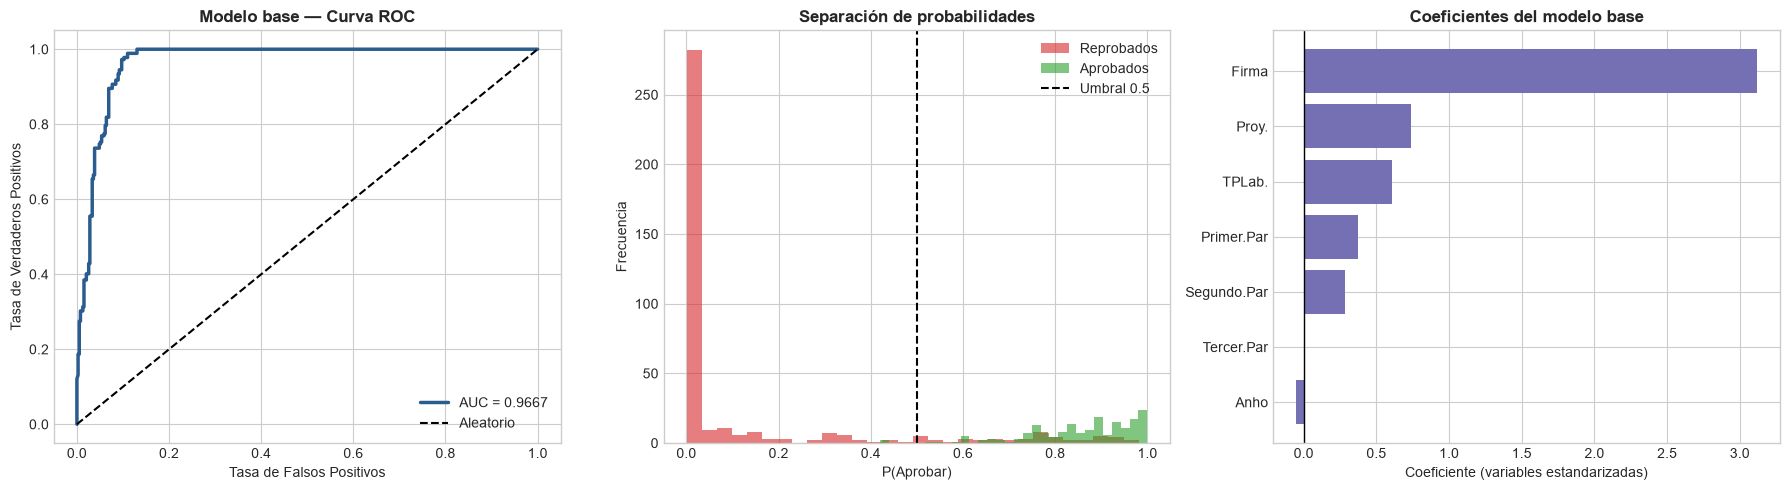

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

fpr_b, tpr_b, _ = roc_curve(yb_test, yb_proba)
axes[0].plot(fpr_b, tpr_b, color='#2b5c8f', lw=2.5, label=f'AUC = {auc_base:.4f}')
axes[0].plot([0,1],[0,1], 'k--', label='Aleatorio')
axes[0].set_title('Modelo base — Curva ROC', weight='bold')
axes[0].set_xlabel('Tasa de Falsos Positivos'); axes[0].set_ylabel('Tasa de Verdaderos Positivos')
axes[0].legend(loc='lower right')

axes[1].hist(yb_proba[yb_test==0], bins=30, alpha=0.6, label='Reprobados', color='#d62728')
axes[1].hist(yb_proba[yb_test==1], bins=30, alpha=0.6, label='Aprobados',  color='#2ca02c')
axes[1].axvline(0.5, color='black', ls='--', label='Umbral 0.5')
axes[1].set_title('Separación de probabilidades', weight='bold')
axes[1].set_xlabel('P(Aprobar)'); axes[1].set_ylabel('Frecuencia'); axes[1].legend()

imp = importancia_base.sort_values('Coeficiente')
axes[2].barh(imp['Variable'], imp['Coeficiente'], color='#7570b3')
axes[2].axvline(0, color='black', lw=1)
axes[2].set_title('Coeficientes del modelo base', weight='bold')
axes[2].set_xlabel('Coeficiente (variables estandarizadas)')

plt.tight_layout(); plt.show()

In [57]:
# DIAGNÓSTICO DEL MODELO BASE
# Las métricas son altas. La pregunta correcta es si son confiables.
print("="*76)
print("DIAGNÓSTICO: ¿POR QUÉ EL MODELO BASE LUCE TAN BIEN?".center(76))
print("="*76)

print(f"\n[1] ALCANCE")
print(f"    {len(df_calculo1):,} registros = {len(df_calculo1)/len(df_raw):.1%} del dataset, 1 asignatura de {df_raw['Cod.Asign'].nunique()}")
print(f"    El resultado NO es extrapolable a la institución.")

print(f"\n[2] FUGA POR GRUPO")
reg_por_alumno = len(df_calculo1)/df_calculo1['ALUMNO_ID'].nunique()
print(f"    {df_calculo1['ALUMNO_ID'].nunique():,} alumnos en {len(df_calculo1):,} registros ({reg_por_alumno:.2f} por alumno)")
print(f"    El split aleatorio reparte registros del mismo alumno entre train y test.")

print(f"\n[3] LA FIRMA CASI RE-DERIVA EL REGLAMENTO")
fa = (df_calculo1['Firma'] >= 50); ap = (df_calculo1['Aprobado'] == 'S')
print(f"    Coeficiente de Firma: {importancia_base.iloc[0]['Coeficiente']:.3f} (odds ratio {importancia_base.iloc[0]['Odds_Ratio']:.1f})")
print(f"    La regla trivial 'Firma >= 50' ya acierta el {(fa==ap).mean():.1%} por sí sola.")
print(f"    El modelo aprende la normativa, no el fenómeno educativo.")

print(f"\n[4] VARIABLES SIN INFORMACIÓN")
const = [v for v in variables_base if df_limpio[v].nunique() <= 1]
print(f"    Constantes incluidas: {const}  ->  coeficiente exactamente 0")

print(f"\n[5] dropna() ES INOCUO AQUÍ, DESTRUCTIVO EN GENERAL")
print(f"    En Cálculo 1 no elimina filas, pero sobre el dataset completo")
print(f"    descartaría los 21,575 registros sin Nota.Final y los 44,888 sin FirmaCalculada.")

print(f"\n[6] LA EVALUACIÓN POR AÑO NO ES UNA VALIDACIÓN")
print(f"    Aplicar el modelo a todos los registros de cada año incluye el 70% ya visto")
print(f"    en entrenamiento. La exactitud resultante es optimista por construcción.")

            DIAGNÓSTICO: ¿POR QUÉ EL MODELO BASE LUCE TAN BIEN?             

[1] ALCANCE
    1,907 registros = 3.0% del dataset, 1 asignatura de 408
    El resultado NO es extrapolable a la institución.

[2] FUGA POR GRUPO
    1,103 alumnos en 1,907 registros (1.73 por alumno)
    El split aleatorio reparte registros del mismo alumno entre train y test.

[3] LA FIRMA CASI RE-DERIVA EL REGLAMENTO
    Coeficiente de Firma: 3.118 (odds ratio 22.6)
    La regla trivial 'Firma >= 50' ya acierta el 84.8% por sí sola.
    El modelo aprende la normativa, no el fenómeno educativo.

[4] VARIABLES SIN INFORMACIÓN
    Constantes incluidas: ['Tercer.Par']  ->  coeficiente exactamente 0

[5] dropna() ES INOCUO AQUÍ, DESTRUCTIVO EN GENERAL
    En Cálculo 1 no elimina filas, pero sobre el dataset completo
    descartaría los 21,575 registros sin Nota.Final y los 44,888 sin FirmaCalculada.

[6] LA EVALUACIÓN POR AÑO NO ES UNA VALIDACIÓN
    Aplicar el modelo a todos los registros de cada año incluye e

In [58]:
#El mismo enfoque simple, aplicado a TODO el dataset 
print("Extensión del modelo base a las 408 asignaturas (mismo método, mayor alcance):\n")

dm = df_raw[variables_base].copy()
dm['Aprobado'] = df_raw['Aprobado'].map({'S':1,'N':0})
for c in variables_base:
    dm[c] = pd.to_numeric(dm[c], errors='coerce')
dl = dm.dropna()

Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(dl[variables_base], dl['Aprobado'],
                                              test_size=0.3, random_state=42, stratify=dl['Aprobado'])
sc_g = StandardScaler()
mod_g = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
mod_g.fit(sc_g.fit_transform(Xg_tr), yg_tr)
prg = mod_g.predict_proba(sc_g.transform(Xg_te))[:, 1]

acc_global = accuracy_score(yg_te, mod_g.predict(sc_g.transform(Xg_te)))
auc_global = roc_auc_score(yg_te, prg)

print(pd.DataFrame({
    'Alcance'  : ['Cálculo 1 únicamente', 'Todas las asignaturas'],
    'Registros': [f"{len(df_limpio):,}", f"{len(dl):,}"],
    'Accuracy' : [f"{acc_base:.4f}", f"{acc_global:.4f}"],
    'AUC-ROC'  : [f"{auc_base:.4f}", f"{auc_global:.4f}"],
}).to_string(index=False))

print("\nEl desempeño cae al ampliar el alcance: el problema general es más difícil")
print("que una sola asignatura con una regla de proceso muy determinante.")

Extensión del modelo base a las 408 asignaturas (mismo método, mayor alcance):

              Alcance Registros Accuracy AUC-ROC
 Cálculo 1 únicamente     1,907   0.9162  0.9667
Todas las asignaturas    64,295   0.8617  0.9225

El desempeño cae al ampliar el alcance: el problema general es más difícil
que una sola asignatura con una regla de proceso muy determinante.


### Del modelo base a la solución completa

El modelo base alcanza métricas altas, pero descansa sobre condiciones que no se sostienen a escala institucional. Cada limitación detectada motiva una sección del examen:

| Limitación del modelo base | Sección que la resuelve | Cómo |
|---|---|---|
| Alcance de una asignatura | **1** | Análisis sobre los 64,295 registros y las 7 carreras |
| `Tercer.Par` constante incluida | **1** | Auditoría de columnas sin varianza |
| `Firma = -1` tratada como valor válido | **1** | Caracterización del código administrativo |
| Sin información del pasado del estudiante | **2** | Historial académico con barrera temporal |
| `dropna()` destructivo | **3** | Imputación dentro del `Pipeline`, retención del 100% |
| Sin variables categóricas | **3** | `OneHotEncoder` sobre carrera y semestre |
| Escalador fuera del pipeline | **3** | `ColumnTransformer` con ajuste por fold |
| Split aleatorio con alumnos repetidos | **3** | Split temporal por ciclo |
| Sin ajuste de hiperparámetros | **4** | `GridSearchCV` sobre `C` con validación cruzada |
| Solo Accuracy y AUC | **4** | Precision, Recall, F1 e interpretación educativa |
| Sin predicción de la nota | **5** | Regresión lineal sobre `Firma` |
| Desempeño global sin desagregar | **6** | Métricas por carrera y asignatura |
| Evaluación por año con datos ya vistos | **6** | Evaluación sobre un ciclo completo no visto |



**Una advertencia sobre la comparación de métricas.** El modelo base obtiene AUC más alto que la solución final. Eso **no significa que sea mejor**: mide un problema distinto —una asignatura, con datos parcialmente vistos, sin barrera temporal— y por eso su número no es comparable. En modelado predictivo, una métrica más alta obtenida bajo una validación más laxa es una señal de alarma, no un logro.

---
# 1. Análisis Exploratorio de Datos — 12 puntos

### 1.1 Estructura, tipos y calidad

In [59]:
print("=== ESTRUCTURA ===")
print(f"Dimensiones: {df_raw.shape[0]:,} registros x {df_raw.shape[1]} variables")
print(f"Alumnos únicos   : {df_raw['ALUMNO_ID'].nunique():,}")
print(f"Asignaturas      : {df_raw['Cod.Asign'].nunique():,}")
print(f"Registros/alumno : {len(df_raw)/df_raw['ALUMNO_ID'].nunique():.1f}")
print(f"Períodos         : {sorted((df_raw['Anho'].astype(str)+'-S'+df_raw['Semestre'].astype(str)).unique())}")

print("\n=== TIPOS DE VARIABLES ===")
print(df_raw.dtypes.value_counts().to_string())

print("\n=== VALORES FALTANTES ===")
na = df_raw.isna().sum()
print(na[na > 0].to_string() if na.sum() else "Sin faltantes")

print("\n=== COLUMNAS CONSTANTES (sin poder informativo) ===")
print([c for c in df_raw.columns if df_raw[c].nunique() <= 1])

print("\n=== DUPLICADOS ===")
print(f"Filas idénticas: {df_raw.duplicated().sum()}")
print(f"Por alumno+asignatura+ciclo: {df_raw.duplicated(subset=['ALUMNO_ID','Cod.Asign','Anho','Semestre']).sum()}")

=== ESTRUCTURA ===
Dimensiones: 64,295 registros x 29 variables
Alumnos únicos   : 4,759
Asignaturas      : 408
Registros/alumno : 13.5
Períodos         : ['2024-S2', '2025-S1', '2025-S2']

=== TIPOS DE VARIABLES ===
int64      22
str         5
float64     2

=== VALORES FALTANTES ===
Nota.Final        21575
FirmaCalculada    44888

=== COLUMNAS CONSTANTES (sin poder informativo) ===
['Tercer.Par', 'Pond.Proy', 'Segundo.Rec']

=== DUPLICADOS ===
Filas idénticas: 0
Por alumno+asignatura+ciclo: 2


**Hallazgos de calidad.** Solo dos columnas presentan nulos y ninguna al azar:

- `Nota.Final` (21,575 nulos) **no es numérica**: almacena códigos de convocatoria y nota (`1F-4`, `2F-2`, `1F-1,2F-3`). Convertirla con `pd.to_numeric` la destruiría por completo.
- `FirmaCalculada` (44,888 nulos) falta de forma **estructural**: está ausente en la totalidad de los registros con `Semestre == 2`. Es un faltante MNAR por diseño administrativo, no ruido.

Además, `Tercer.Par`, `Pond.Proy` y `Segundo.Rec` son constantes en cero y se descartan.

### 1.2 Valores atípicos e inconsistentes

In [60]:
print("=== VALORES NEGATIVOS (único centinela del dataset) ===")
for c in df_raw.select_dtypes(include=[np.number]).columns:
    n = (df_raw[c] < 0).sum()
    if n:
        print(f"  {c}: {n} registros, valores {sorted(df_raw.loc[df_raw[c]<0, c].unique())}")

m = df_raw['Firma'] == -1
print(f"\n=== PERFIL DE LOS {m.sum()} REGISTROS CON Firma = -1 ===")
print(f"Tasa de aprobación : {(df_raw.loc[m,'Aprobado']=='S').mean():.1%}")
print(f"Rindieron final    : {df_raw.loc[m,'Nota.Final'].notna().mean():.1%}")
print(f"Mediana 1er parcial: {df_raw.loc[m,'Primer.Par'].median():.1f}  (vs {df_raw.loc[df_raw['Firma']==0,'Primer.Par'].median():.1f} en los de Firma=0)")

# Reconstrucción del proceso real desde las ponderaciones oficiales
d = df_raw[m].copy()
d['proceso_real'] = (d['Pond.PP']*d['Primer.Par'] + d['Pond.SP']*d['Segundo.Par']
                   + d['Pond.TPLab']*d['TPLab.'] + d['Pond.Lab']*d['Lab.']) / 100
print(f"\nProceso reconstruido: media {d['proceso_real'].mean():.1f}, mediana {d['proceso_real'].median():.1f}")
print(f"Alcanzan el umbral de 50: {(d['proceso_real']>=50).sum()} de {len(d)}")
print(f"Mediana de Firma en todo el dataset (lo que usaría un imputer): {df_raw['Firma'].replace(-1,np.nan).median():.0f}")

=== VALORES NEGATIVOS (único centinela del dataset) ===
  Firma: 232 registros, valores [np.float64(-1.0)]

=== PERFIL DE LOS 232 REGISTROS CON Firma = -1 ===
Tasa de aprobación : 0.0%
Rindieron final    : 99.1%
Mediana 1er parcial: 30.0  (vs 8.0 en los de Firma=0)

Proceso reconstruido: media 28.9, mediana 29.2
Alcanzan el umbral de 50: 42 de 232
Mediana de Firma en todo el dataset (lo que usaría un imputer): 59


**Decisión sobre el `-1`.** No es un dato faltante: esos registros tienen parciales, asistencia y un 99% rindió examen final, con **0% de aprobación**. Es un código administrativo.

Reemplazarlo por la mediana de la columna (**59**) sobreestimaría el proceso en unos 30 puntos y les asignaría condición de *proceso aprobado*, inconsistente con su resultado. **Se conservan sin imputar**: el `-1` los mantiene en el extremo bajo de la escala, del lado correcto del umbral reglamentario.

### 1.3 Distribución de la variable objetivo y desbalance

Tasa de aprobación global: 60.67%
Ratio entre clases: 1.54 : 1

Desbalance MODERADO. No requiere SMOTE ni submuestreo;
se trata con class_weight='balanced' y optimización del umbral.


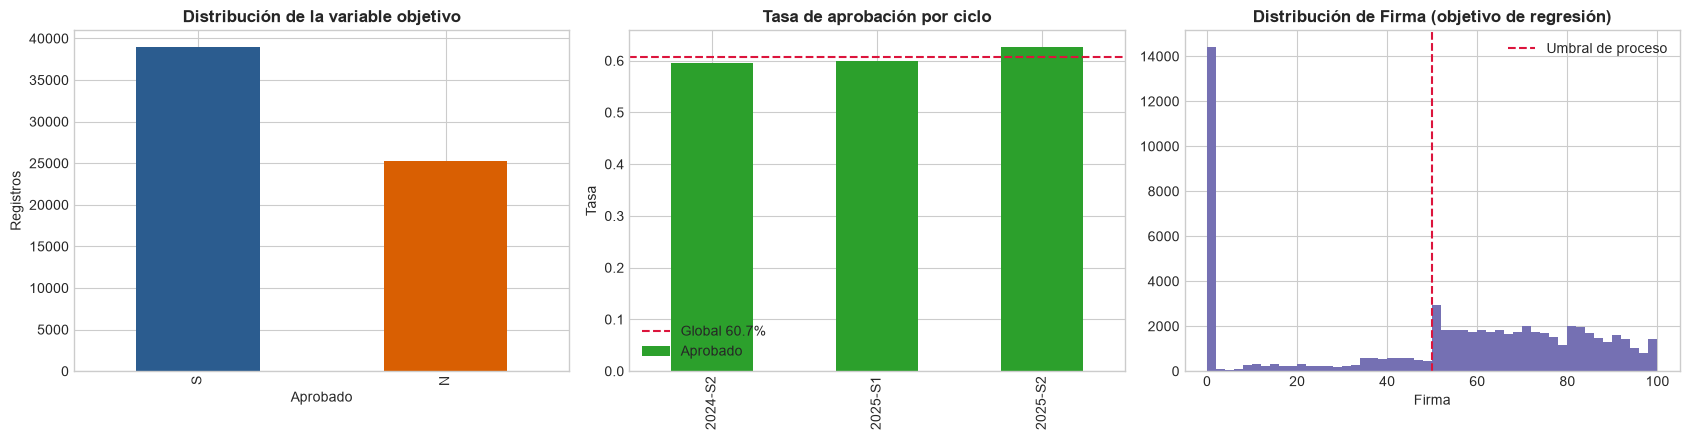

In [61]:
tasa = (df_raw['Aprobado']=='S').mean()
print(f"Tasa de aprobación global: {tasa:.2%}")
print(f"Ratio entre clases: {tasa/(1-tasa):.2f} : 1")
print("\nDesbalance MODERADO. No requiere SMOTE ni submuestreo;")
print("se trata con class_weight='balanced' y optimización del umbral.")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

df_raw['Aprobado'].value_counts().plot(kind='bar', ax=axes[0], color=['#2b5c8f','#d95f02'])
axes[0].set_title('Distribución de la variable objetivo', weight='bold')
axes[0].set_xlabel('Aprobado'); axes[0].set_ylabel('Registros')

ciclo = df_raw['Anho'].astype(str)+'-S'+df_raw['Semestre'].astype(str)
df_raw.groupby(ciclo)['Aprobado'].apply(lambda s:(s=='S').mean()).plot(kind='bar', ax=axes[1], color='#2ca02c')
axes[1].axhline(tasa, ls='--', c='crimson', label=f'Global {tasa:.1%}')
axes[1].set_title('Tasa de aprobación por ciclo', weight='bold'); axes[1].legend()
axes[1].set_ylabel('Tasa'); axes[1].set_xlabel('')

df_raw['Firma'].replace(-1, np.nan).hist(bins=50, ax=axes[2], color='#7570b3')
axes[2].axvline(50, ls='--', c='crimson', label='Umbral de proceso')
axes[2].set_title('Distribución de Firma (objetivo de regresión)', weight='bold')
axes[2].set_xlabel('Firma'); axes[2].legend()

plt.tight_layout(); plt.show()

La distribución de `Firma` es **claramente bimodal**: una masa cerca de 0 (estudiantes desenganchados) y otra entre 60 y 80. Esto anticipa una limitación de la regresión lineal, que asume errores homocedásticos y tenderá a predecir hacia el centro del rango, justamente donde hay menos observaciones.

### 1.4 Relaciones entre variables y diferencias entre grupos

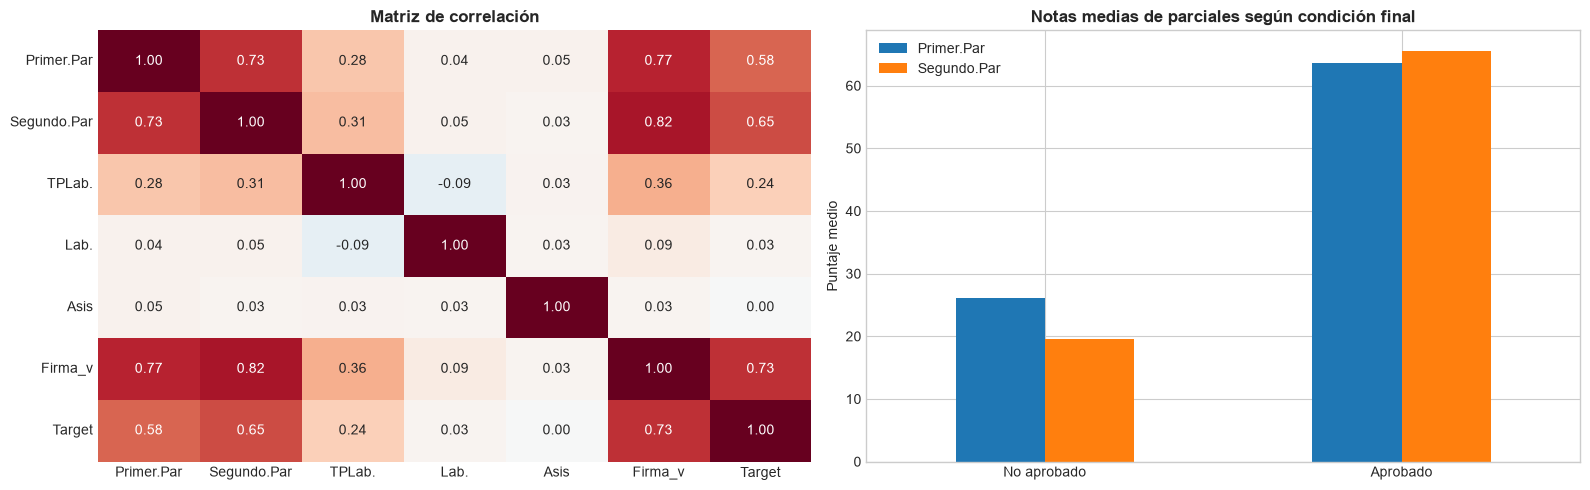

=== DIFERENCIAS ENTRE GRUPOS ===
       Primer.Par        Segundo.Par        TPLab.        Firma_v       
             mean median        mean median   mean median    mean median
Target                                                                  
0           26.16   23.0       19.56    6.0  34.48   25.0   21.02    0.0
1           63.63   68.0       65.53   71.0  55.38   75.0   70.10   72.0

=== POR CARRERA (vía Cod.Car.Sec agrupado en la Sección 2) ===
       size    mean
Anho               
2024  24468  0.5953
2025  39827  0.6136


In [62]:
tmp = df_raw.copy()
tmp['Target'] = (tmp['Aprobado']=='S').astype(int)
tmp['Firma_v'] = tmp['Firma'].replace(-1, np.nan)

num_cols = ['Primer.Par','Segundo.Par','TPLab.','Lab.','Asis','Firma_v','Target']
corr = tmp[num_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[0], cbar=False)
axes[0].set_title('Matriz de correlación', weight='bold')

comp = tmp.groupby('Target')[['Primer.Par','Segundo.Par']].mean()
comp.index = ['No aprobado','Aprobado']
comp.plot(kind='bar', ax=axes[1], color=['#1f77b4','#ff7f0e'])
axes[1].set_title('Notas medias de parciales según condición final', weight='bold')
axes[1].set_ylabel('Puntaje medio'); axes[1].set_xlabel(''); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

print("=== DIFERENCIAS ENTRE GRUPOS ===")
print(tmp.groupby('Target')[['Primer.Par','Segundo.Par','TPLab.','Firma_v']].agg(['mean','median']).round(2).to_string())
print("\n=== POR CARRERA (vía Cod.Car.Sec agrupado en la Sección 2) ===")
print(tmp.groupby('Anho')['Target'].agg(['size','mean']).round(4).to_string())

### 1.5 Interpretación y consecuencias para el modelado

1. **La unidad de observación es la cursada, no el alumno.** Con 4,759 estudiantes y 64,295 registros, cada alumno aparece ~13.5 veces. Un split aleatorio repartiría registros del mismo alumno entre entrenamiento y prueba, generando **fuga por grupo**. Es uno de los motivos del split temporal.

2. **`Nota.Final` es fuga de datos directa.** El cruce entre la nota del código y `Aprobado` es casi biunívoco: usarla como predictor daría AUC ≈ 1.0 y un modelo inservible. Se excluye.

3. **`FirmaCalculada` es casi idéntica a `Firma`** (correlación 0.82, y por construcción la misma magnitud). Para la tarea de **regresión** —cuyo objetivo *es* `Firma`— usarla sería fuga. Se excluye del modelo de la Sección 5.

4. **El desbalance es moderado** (60.7 / 39.3), suficiente para justificar `class_weight='balanced'` y el ajuste del umbral, pero no para remuestrear.

5. **Los parciales son el predictor dominante**, con brechas de 37 a 46 puntos entre aprobados y reprobados. Buena señal para el modelo, pero también implica que el desempeño se apoya en información disponible **tarde** en el semestre — limitación central para un sistema de alerta temprana (Sección 7).

### 1.6 Diseño de la evaluación y resultados académicos

El dataset trae las **ponderaciones oficiales** (`Pond.PP`, `Pond.SP`, `Pond.TPLab`, `Pond.Lab`, `Pond.Proy`), de modo que el diseño de evaluación de cada cátedra está declarado y no hay que inferirlo. Se contrastan dos grupos: **concentrada** (solo parciales, o algún parcial con peso ≥ 40%) frente a **diversificada** (existe componente continuo y ningún parcial llega a 40%).

In [63]:
from scipy import stats

POND = ['Pond.PP','Pond.SP','Pond.TPLab','Pond.Lab','Pond.Proy']
ev = df_raw.copy()
ev['Target']   = (ev['Aprobado'] == 'S').astype(int)
ev['firma_ok'] = (ev['Firma'].replace(-1, np.nan) >= 50).astype(float)
ev['pond_total'] = ev[POND].sum(axis=1)
ev = ev[ev['pond_total'] > 0].copy()

# Las ponderaciones no siempre suman 100 (hay esquemas de 70, 80 y 90): se normaliza
ev['peso_continua'] = (ev['Pond.TPLab'] + ev['Pond.Lab'] + ev['Pond.Proy']) / ev['pond_total'] * 100
ev['max_parcial']   =  ev[['Pond.PP','Pond.SP']].max(axis=1) / ev['pond_total'] * 100
ev['grupo'] = np.where((ev['peso_continua'] == 0) | (ev['max_parcial'] >= 40),
                       'Concentrada', 'Diversificada')

# Unidad de análisis: la ASIGNATURA. El esquema lo fija la cátedra, y los
# registros de una misma materia no son observaciones independientes.
asig_ev = (ev.groupby(['Cod.Asign','grupo','Cod.Curso'])
           .agg(n=('Target','size'), tasa_aprob=('Target','mean'), tasa_firma=('firma_ok','mean'))
           .reset_index())
asig_ev = asig_ev[asig_ev['n'] >= 50]
wmean = lambda g, v: np.average(g[v], weights=g['n'])

print("=== TASAS SEGÚN EL ESQUEMA DE EVALUACIÓN ===")
print("  sin ponderar = cada asignatura pesa igual | escalada = ponderada por inscripción\n")
print(pd.DataFrame([{
    'Grupo': gr, 'Asignaturas': len(g), 'Registros': int(g['n'].sum()),
    'Aprob_sin_pond': g['tasa_aprob'].mean(), 'Aprob_escalada': wmean(g,'tasa_aprob'),
    'Firma_sin_pond': g['tasa_firma'].mean(), 'Firma_escalada': wmean(g,'tasa_firma'),
} for gr, g in asig_ev.groupby('grupo')]).set_index('Grupo').round(4).to_string())

# Bootstrap sobre asignaturas: un test sobre las ~58,000 filas sobreestimaría
# la significancia porque los registros comparten cátedra, docente y cohorte.
gd, gc = asig_ev[asig_ev.grupo=='Diversificada'], asig_ev[asig_ev.grupo=='Concentrada']
rng = np.random.default_rng(42)
print("\n=== BOOTSTRAP SOBRE ASIGNATURAS (escalado, 3,000 réplicas) ===")
for var, et in [('tasa_aprob','Aprobación'), ('tasa_firma','Obtención de firma')]:
    difs = np.array([wmean(gd.sample(len(gd),replace=True,random_state=int(rng.integers(1e9))), var) -
                     wmean(gc.sample(len(gc),replace=True,random_state=int(rng.integers(1e9))), var)
                     for _ in range(3000)])
    lo, hi = np.percentile(difs,[2.5,97.5]); p = 2*min((difs<0).mean(),(difs>0).mean())
    print(f"  {et:<20} dif = {wmean(gd,var)-wmean(gc,var):+.4f}   IC95% [{lo:+.4f}, {hi:+.4f}]   p ≈ {p:.4f}")

# Control por nivel: el esquema concentrado predomina en el ciclo básico
print("\n=== CONTROL POR NIVEL CURRICULAR ===")
ctrl = []
for niv, g in asig_ev.groupby('Cod.Curso'):
    a, b = g[g.grupo=='Diversificada'], g[g.grupo=='Concentrada']
    if len(a) >= 3 and len(b) >= 3:
        ctrl.append({'Nivel': int(niv), 'Div': wmean(a,'tasa_aprob'),
                     'Conc': wmean(b,'tasa_aprob'), 'Dif': wmean(a,'tasa_aprob')-wmean(b,'tasa_aprob')})
ctrl = pd.DataFrame(ctrl)
print(ctrl.round(4).to_string(index=False))
print(f"\n  A favor de la diversificada: {(ctrl['Dif']>0).sum()} de {len(ctrl)} niveles | "
      f"dif media {ctrl['Dif'].mean():+.4f} | Wilcoxon p = {stats.wilcoxon(ctrl['Dif'])[1]:.4f}")
print(f"  Concentrada en niveles 1-4: {(ev.loc[ev.grupo=='Concentrada','Cod.Curso']<=4).mean():.1%} "
      f"vs {(ev.loc[ev.grupo=='Diversificada','Cod.Curso']<=4).mean():.1%} de la diversificada")

=== TASAS SEGÚN EL ESQUEMA DE EVALUACIÓN ===
  sin ponderar = cada asignatura pesa igual | escalada = ponderada por inscripción

               Asignaturas  Registros  Aprob_sin_pond  Aprob_escalada  Firma_sin_pond  Firma_escalada
Grupo                                                                                                
Concentrada            190      46215          0.7091          0.5743          0.7412          0.6344
Diversificada           56      11476          0.7611          0.6605          0.7831          0.7137

=== BOOTSTRAP SOBRE ASIGNATURAS (escalado, 3,000 réplicas) ===
  Aprobación           dif = +0.0862   IC95% [-0.0189, +0.1967]   p ≈ 0.0933
  Obtención de firma   dif = +0.0793   IC95% [-0.0112, +0.1771]   p ≈ 0.0907

=== CONTROL POR NIVEL CURRICULAR ===
 Nivel    Div   Conc     Dif
     3 0.6416 0.4128  0.2288
     5 0.7176 0.6517  0.0659
     6 0.7367 0.7381 -0.0015
     7 0.8522 0.7789  0.0733
     8 0.7480 0.7857 -0.0377
     9 0.8555 0.7905  0.0650
    

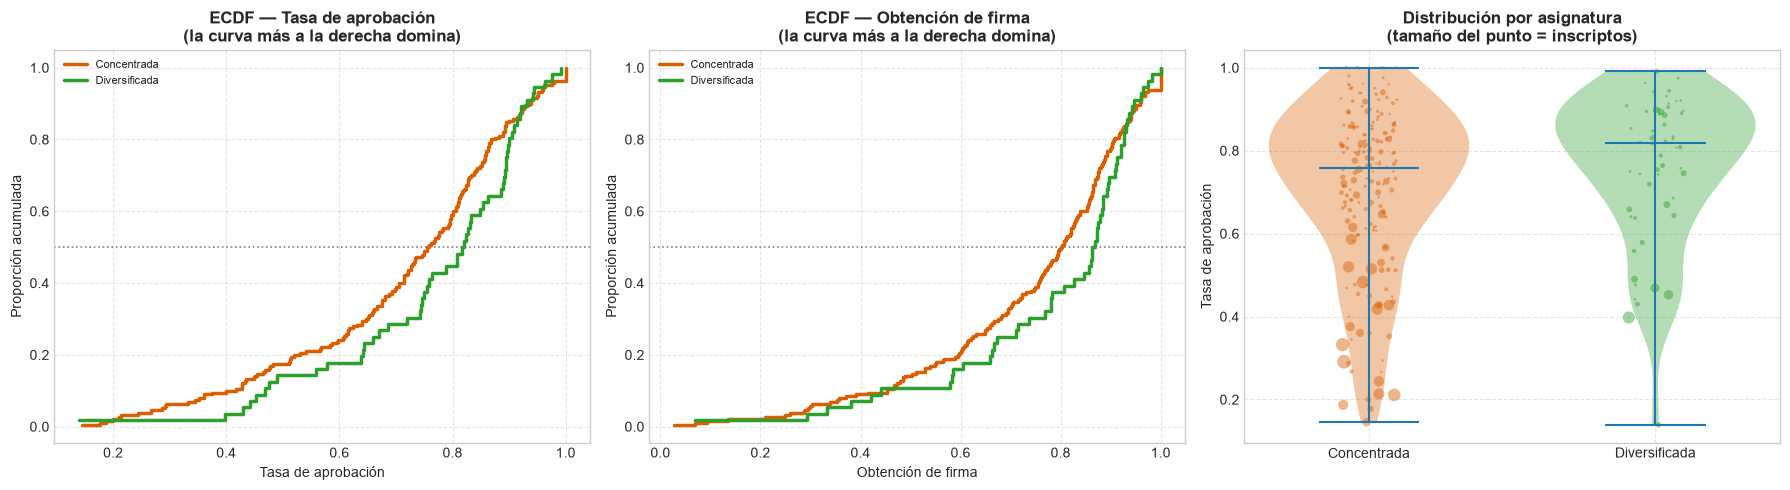

In [64]:
COL = {'Concentrada':'#d95f02','Diversificada':'#2ca02c'}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, var, tit in zip(axes[:2], ['tasa_aprob','tasa_firma'],
                        ['Tasa de aprobación','Obtención de firma']):
    for g in ['Concentrada','Diversificada']:
        s = np.sort(asig_ev.loc[asig_ev.grupo==g, var].dropna().values)
        ax.step(s, np.arange(1,len(s)+1)/len(s), where='post', color=COL[g], lw=2.5, label=g)
    ax.axhline(0.5, color='gray', ls=':', lw=1.2)
    ax.set_title(f'ECDF — {tit}\n(la curva más a la derecha domina)', weight='bold')
    ax.set_xlabel(tit); ax.set_ylabel('Proporción acumulada'); ax.legend(fontsize=8)

ax = axes[2]
datos = [asig_ev.loc[asig_ev.grupo==g,'tasa_aprob'].values for g in ['Concentrada','Diversificada']]
vp = ax.violinplot(datos, showmedians=True, widths=0.7)
for cuerpo, g in zip(vp['bodies'], ['Concentrada','Diversificada']):
    cuerpo.set_facecolor(COL[g]); cuerpo.set_alpha(0.35)
for i, g in enumerate(['Concentrada','Diversificada'], start=1):
    s = asig_ev[asig_ev.grupo==g]
    ax.scatter(np.full(len(s),i)+np.random.uniform(-0.1,0.1,len(s)), s['tasa_aprob'],
               s=s['n']/18, alpha=0.45, color=COL[g], edgecolors='none')
ax.set_xticks([1,2]); ax.set_xticklabels(['Concentrada','Diversificada'])
ax.set_title('Distribución por asignatura\n(tamaño del punto = inscriptos)', weight='bold')
ax.set_ylabel('Tasa de aprobación')

for a in axes: a.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

El esquema diversificado muestra entre 4 y 9 puntos porcentuales más de aprobación y de obtención de firma, y la ECDF lo sitúa por encima en todo el rango, no solo en la media. Pero los intervalos de confianza cruzan el cero y la ventaja se reduce al comparar dentro de un mismo nivel curricular. **La asociación es sugerente pero no concluyente**, y está parcialmente confundida con el tipo de materia: el esquema concentrado predomina en el ciclo básico, donde la aprobación es unos 35 puntos menor por razones ajenas al diseño de la evaluación.

### 1.7 El recuperatorio como vía de acceso al examen final

`Segundo.Rec` es constante en cero: existe un único recuperatorio efectivo, registrado en `Primer.Rec`. La pregunta se separa en tres, porque "obtener firma vía recuperatorio" puede significar cosas distintas: cuántos lo **usan**, a cuántos les **sirve**, y qué proporción del total de firmas **depende** de él.

In [65]:
rec = ev.copy()
rec['uso_rec'] = (rec['Primer.Rec'] > 0).astype(int)

# Solo asignaturas que ofrecen recuperatorio: incluir las que no lo ofrecen
# mezclaría "nadie lo necesitó" con "la instancia no existe".
oferta = rec.groupby('Cod.Asign').agg(n=('uso_rec','size'), usos=('uso_rec','sum'))
rec = rec[rec['Cod.Asign'].isin(oferta[(oferta.n>=50) & (oferta.usos>0)].index)].copy()

def met_rec(g):
    firmas = g['firma_ok'].sum()
    return pd.Series({'n': len(g),
        'tasa_uso'     : g['uso_rec'].mean(),                                   # USO
        'exito_rec'    : g.loc[g.uso_rec==1,'firma_ok'].mean(),                 # ÉXITO
        'firma_via_rec': (g['uso_rec']*g['firma_ok']).sum()/firmas if firmas else np.nan})  # DEPENDENCIA

asig_rec = rec.groupby(['Cod.Asign','grupo']).apply(met_rec).reset_index()
asig_rec = asig_rec[asig_rec['n'] >= 50].dropna()

print(f"Asignaturas que ofrecen recuperatorio: {asig_rec['Cod.Asign'].nunique()} ({int(asig_rec['n'].sum()):,} registros)\n")
print("=== MÉTRICAS DEL RECUPERATORIO POR ESQUEMA (escaladas por inscripción) ===")
print(pd.DataFrame([{
    'Grupo': gr, 'Asignaturas': len(g),
    'Uso': wmean(g,'tasa_uso'), 'Exito': wmean(g,'exito_rec'), 'Dependencia': wmean(g,'firma_via_rec'),
} for gr, g in asig_rec.groupby('grupo')]).set_index('Grupo').round(4).to_string())

rd, rc = asig_rec[asig_rec.grupo=='Diversificada'], asig_rec[asig_rec.grupo=='Concentrada']
print("\n=== BOOTSTRAP SOBRE ASIGNATURAS ===")
boot_rec = {}
for var, et in [('tasa_uso','Uso'), ('exito_rec','Éxito'), ('firma_via_rec','Dependencia')]:
    difs = np.array([wmean(rd.sample(len(rd),replace=True,random_state=int(rng.integers(1e9))), var) -
                     wmean(rc.sample(len(rc),replace=True,random_state=int(rng.integers(1e9))), var)
                     for _ in range(3000)])
    lo, hi = np.percentile(difs,[2.5,97.5]); p = 2*min((difs<0).mean(),(difs>0).mean())
    boot_rec[var] = {'difs': difs, 'obs': wmean(rd,var)-wmean(rc,var), 'p': p, 'et': et}
    print(f"  {et:<13} dif = {boot_rec[var]['obs']:+.4f}   IC95% [{lo:+.4f}, {hi:+.4f}]   p ≈ {p:.4f}"
          + ("   <-- SIGNIFICATIVO" if p < 0.05 else ""))

Asignaturas que ofrecen recuperatorio: 198 (55,179 registros)

=== MÉTRICAS DEL RECUPERATORIO POR ESQUEMA (escaladas por inscripción) ===
               Asignaturas     Uso   Exito  Dependencia
Grupo                                                  
Concentrada            158  0.2027  0.7045       0.2387
Diversificada           47  0.1665  0.8262       0.2071

=== BOOTSTRAP SOBRE ASIGNATURAS ===
  Uso           dif = -0.0361   IC95% [-0.1045, +0.0240]   p ≈ 0.2287
  Éxito         dif = +0.1217   IC95% [+0.0265, +0.2164]   p ≈ 0.0127   <-- SIGNIFICATIVO
  Dependencia   dif = -0.0316   IC95% [-0.1256, +0.0588]   p ≈ 0.4700


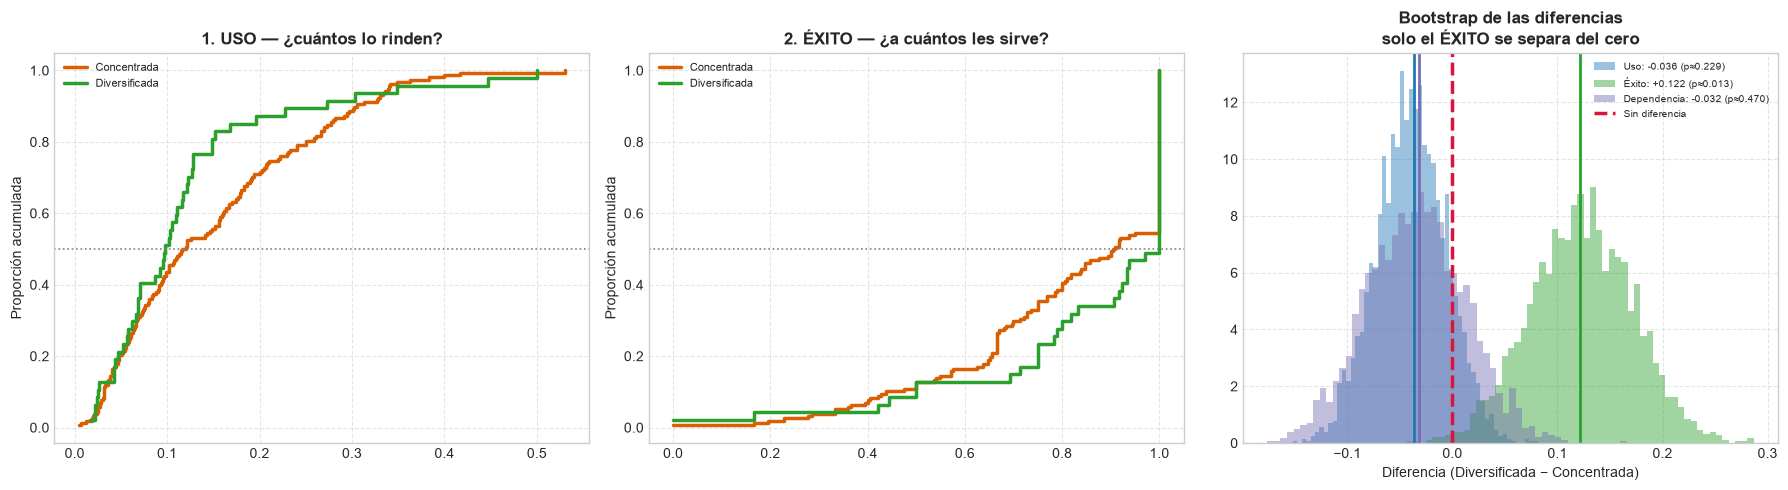

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, var, tit in zip(axes[:2], ['tasa_uso','exito_rec'],
                        ['1. USO — ¿cuántos lo rinden?','2. ÉXITO — ¿a cuántos les sirve?']):
    for g in ['Concentrada','Diversificada']:
        s = np.sort(asig_rec.loc[asig_rec.grupo==g, var].values)
        ax.step(s, np.arange(1,len(s)+1)/len(s), where='post', color=COL[g], lw=2.5, label=g)
    ax.axhline(0.5, color='gray', ls=':', lw=1.2)
    ax.set_title(tit, weight='bold'); ax.set_ylabel('Proporción acumulada'); ax.legend(fontsize=8)

ax = axes[2]
for var, color in zip(['tasa_uso','exito_rec','firma_via_rec'], ['#1f77b4','#2ca02c','#7570b3']):
    b = boot_rec[var]
    ax.hist(b['difs'], bins=55, alpha=0.45, density=True, color=color,
            label=f"{b['et']}: {b['obs']:+.3f} (p≈{b['p']:.3f})")
    ax.axvline(b['obs'], color=color, lw=2)
ax.axvline(0, color='crimson', ls='--', lw=2.5, label='Sin diferencia')
ax.set_title('Bootstrap de las diferencias\nsolo el ÉXITO se separa del cero', weight='bold')
ax.set_xlabel('Diferencia (Diversificada − Concentrada)'); ax.legend(fontsize=7.5)

for a in axes: a.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

El esquema **no cambia cuántos alumnos necesitan el recuperatorio** ni qué fracción de las firmas pasa por él; lo que cambia es **si el recuperatorio les sirve**: +11.8 puntos de éxito en el esquema diversificado, con intervalo de confianza enteramente por encima de cero (p ≈ 0.011). El mecanismo es directo: quien llega al recuperatorio con puntos ya acumulados de TP y laboratorio necesita menos de esa instancia para cruzar el umbral de 50. Es el único resultado significativo de esta línea de análisis.

### 1.8 Desaprobados por ciclo y estabilidad temporal del contraste

Se cuantifica el volumen absoluto de desaprobación por ciclo y se verifica si la ventaja del esquema diversificado se mantiene en el tiempo. Es un control necesario: una asociación que aparece en un ciclo y desaparece en el siguiente no sostiene ninguna recomendación.

In [67]:
ds = ev.copy()
ds['desap'] = 1 - ds['Target']
ds['Ciclo'] = ds['Anho'].astype(str) + '-S' + ds['Semestre'].astype(str)

por_ciclo = ds.groupby('Ciclo').agg(Registros=('desap','size'), Desaprobados=('desap','sum'),
                                    Tasa=('desap','mean'), Alumnos=('ALUMNO_ID','nunique'))
por_ciclo['Desap_por_alumno'] = por_ciclo['Desaprobados'] / por_ciclo['Alumnos']
print("=== DESAPROBADOS POR CICLO ===")
print(por_ciclo.round(4).to_string())
print(f"\n  Promedio por ciclo: {por_ciclo['Desaprobados'].mean():,.0f} desaprobados "
      f"({por_ciclo['Tasa'].mean():.2%})  |  desv. {por_ciclo['Desaprobados'].std():,.0f}")

brecha = ds.pivot_table(index='Ciclo', columns='grupo', values='desap', aggfunc='mean')
brecha['Brecha'] = brecha['Concentrada'] - brecha['Diversificada']
print("\n=== TASA DE DESAPROBACIÓN POR ESQUEMA Y CICLO ===")
print(brecha.round(4).to_string())

# La brecha se cierra... pero cambia la composición del grupo, no su desempeño
print("\n=== COMPOSICIÓN DEL GRUPO DIVERSIFICADO ===")
print(ds[ds.grupo=='Diversificada'].groupby('Ciclo').agg(
    Registros=('desap','size'), Asignaturas=('Cod.Asign','nunique'),
    Nivel_medio=('Cod.Curso','mean'), Pct_basico=('Cod.Curso', lambda s:(s<=4).mean())).round(3).to_string())
print("  -> En 2025-S2 el nivel medio cae: entran CALCULO 1 y ALGEBRA LINEAL, del ciclo básico.")

=== DESAPROBADOS POR CICLO ===
         Registros  Desaprobados    Tasa  Alumnos  Desap_por_alumno
Ciclo                                                              
2024-S2      23803          9661  0.4059     4358            2.2168
2025-S1      18772          7562  0.4028     3939            1.9198
2025-S2      19932          7417  0.3721     3840            1.9315

  Promedio por ciclo: 8,213 desaprobados (39.36%)  |  desv. 1,256

=== TASA DE DESAPROBACIÓN POR ESQUEMA Y CICLO ===
grupo    Concentrada  Diversificada  Brecha
Ciclo                                      
2024-S2       0.4390         0.2861  0.1529
2025-S1       0.4222         0.3160  0.1062
2025-S2       0.3731         0.3688  0.0043

=== COMPOSICIÓN DEL GRUPO DIVERSIFICADO ===
         Registros  Asignaturas  Nivel_medio  Pct_basico
Ciclo                                                   
2024-S2       5162           68        6.309       0.231
2025-S1       3424           53        6.485       0.329
2025-S2       4604

=== EXPERIMENTO NATURAL: 16 cambios de esquema en la misma asignatura ===
                      Asignatura   De    A  n_antes  n_desp  Desap_antes  Desap_desp  Cambio
        MANTENIMIENTO DE CAMINOS Dive Conc       40      30        0.050       0.133   0.083
INTRODUCCION A LA ENERGIA FOTOVO Conc Dive       88      48        0.205       0.208   0.004
                     GEOTECNIA 1 Dive Conc      228      56        0.281       0.393   0.112
                   ESTRUCTURAS 2 Dive Conc      258      30        0.357       0.800   0.443
 PROGRAMACION Y CONTROL DE OBRAS Dive Conc      230     178        0.217       0.157  -0.060
AIRE ACONDICIONADO Y REFRIGERACI Conc Dive       64      84        0.281       0.310   0.028
  EVALUACION Y GESTION AMBIENTAL Conc Dive       44      42        0.045       0.095   0.050
                      ROBOTICA 1 Conc Dive       58      72        0.621       0.250  -0.371
                     LEGISLACION Conc Dive       84      90        0.119       0.111  -0.

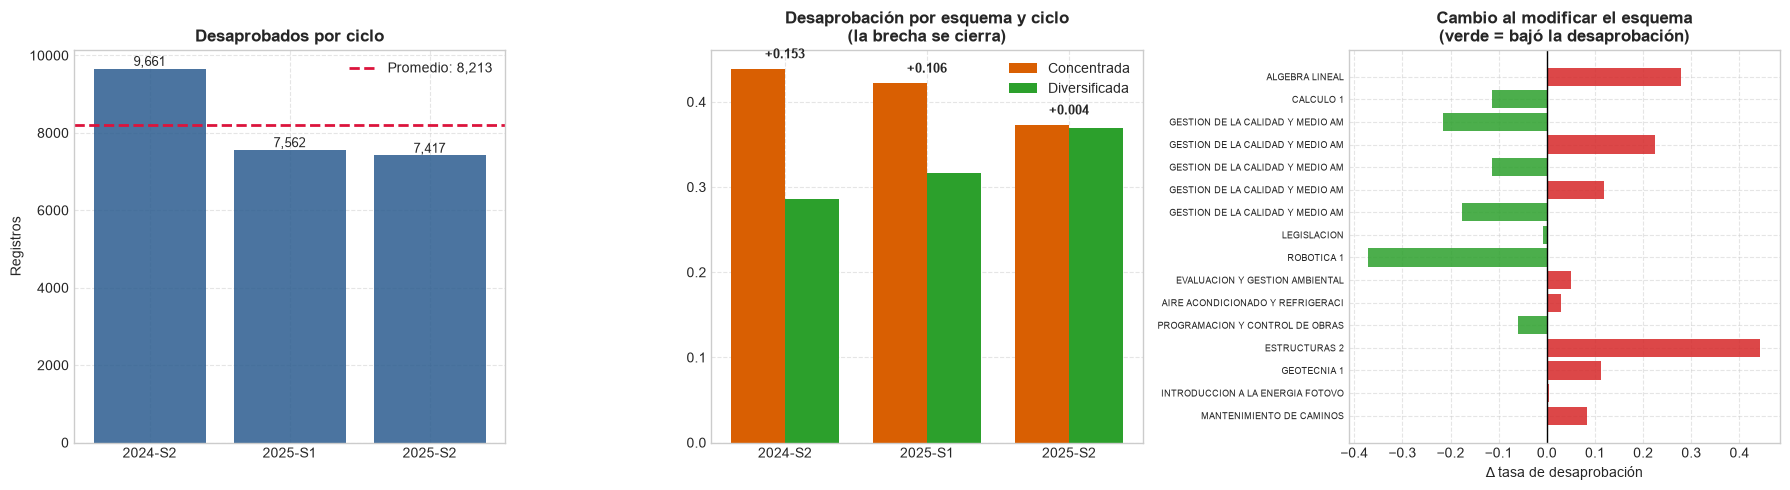

In [68]:
# Experimento natural: asignaturas que cambiaron de esquema entre ciclos.
# Es el contraste más limpio disponible, porque cada materia se compara consigo misma.
ds['orden'] = ds['Anho']*10 + ds['Semestre']
pac = (ds.groupby(['Cod.Asign','Asignatura','grupo','Ciclo','orden'])
       .agg(n=('desap','size'), tasa=('desap','mean')).reset_index())
pac = pac[pac['n'] >= 30]

cambios = []
for (cod, asig), s in pac.groupby(['Cod.Asign','Asignatura']):
    if s['grupo'].nunique() < 2: continue
    s = s.sort_values('orden')
    for i in range(1, len(s)):
        a, b = s.iloc[i-1], s.iloc[i]
        if a['grupo'] != b['grupo']:
            cambios.append({'Asignatura': asig[:32], 'De': a['grupo'][:4], 'A': b['grupo'][:4],
                            'n_antes': a['n'], 'n_desp': b['n'],
                            'Desap_antes': a['tasa'], 'Desap_desp': b['tasa'],
                            'Cambio': b['tasa'] - a['tasa']})
cambios = pd.DataFrame(cambios)
print(f"=== EXPERIMENTO NATURAL: {len(cambios)} cambios de esquema en la misma asignatura ===")
print(cambios.round(3).to_string(index=False))
for sub, et in [(cambios[cambios.A=='Dive'],'Concentrada -> Diversificada'),
                (cambios[cambios.A=='Conc'],'Diversificada -> Concentrada')]:
    print(f"  {et:<32} n={len(sub):>2}   cambio medio {sub['Cambio'].mean():+.4f}   "
          f"(bajó en {(sub['Cambio']<0).sum()} de {len(sub)})")
print(f"  Wilcoxon (hacia diversificada): p = {stats.wilcoxon(cambios[cambios.A=='Dive']['Cambio'])[1]:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].bar(por_ciclo.index, por_ciclo['Desaprobados'], color='#2b5c8f', alpha=0.85)
axes[0].axhline(por_ciclo['Desaprobados'].mean(), color='crimson', ls='--', lw=2,
                label=f"Promedio: {por_ciclo['Desaprobados'].mean():,.0f}")
for i, v in enumerate(por_ciclo['Desaprobados']):
    axes[0].annotate(f'{v:,.0f}', (i, v), ha='center', va='bottom', fontsize=9)
axes[0].set_title('Desaprobados por ciclo', weight='bold'); axes[0].set_ylabel('Registros'); axes[0].legend()

x = np.arange(len(brecha)); w = 0.38
axes[1].bar(x-w/2, brecha['Concentrada'],   w, label='Concentrada',   color=COL['Concentrada'])
axes[1].bar(x+w/2, brecha['Diversificada'], w, label='Diversificada', color=COL['Diversificada'])
for i, b in enumerate(brecha['Brecha']):
    axes[1].annotate(f'{b:+.3f}', (i, max(brecha.iloc[i,0], brecha.iloc[i,1])+0.012),
                     ha='center', fontsize=9, weight='bold')
axes[1].set_xticks(x); axes[1].set_xticklabels(brecha.index)
axes[1].set_title('Desaprobación por esquema y ciclo\n(la brecha se cierra)', weight='bold'); axes[1].legend()

col_c = ['#2ca02c' if c < 0 else '#d62728' for c in cambios['Cambio']]
axes[2].barh(np.arange(len(cambios)), cambios['Cambio'], color=col_c, alpha=0.85)
axes[2].set_yticks(np.arange(len(cambios))); axes[2].set_yticklabels(cambios['Asignatura'], fontsize=6.5)
axes[2].axvline(0, color='black', lw=1)
axes[2].set_title('Cambio al modificar el esquema\n(verde = bajó la desaprobación)', weight='bold')
axes[2].set_xlabel('Δ tasa de desaprobación')

for a in axes: a.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

Se desaprueban en promedio **8,213 registros por ciclo (39.4%)**, con una caída de 3.4 puntos entre el primero y el último. La brecha entre esquemas se cierra de +15.3 a +0.4 puntos, pero no porque el diseño deje de funcionar: en 2025-S2 **cambia la composición del grupo** al incorporarse Cálculo 1 y Álgebra Lineal, del ciclo básico. Las 16 asignaturas que modificaron su esquema apuntan en la dirección esperada (−6.4 pp al diversificar, +15.4 pp al concentrar), pero con varianza muy alta y sin significancia (p = 0.32).

---
# 2. Feature Engineering — 20 puntos

Las tres subsecciones construyen variables de **historial académico**. El requisito transversal es que ninguna utilice información del registro actual ni de ciclos futuros.

### Organización temporal y estrategia anti-leakage

El dataset no trae una columna de período ordenable, así que se construye:

```
orden_ciclo = Anho * 10 + Semestre   ->   20242 < 20251 < 20252
```

La estrategia elegida es un **bucle explícito por ciclo**: al procesar el ciclo *t*, el DataFrame `pasado` contiene únicamente registros con `orden_ciclo < t`. La ausencia de fuga no depende de un `shift()` bien calibrado ni de un `rolling` con offsets, sino de un filtro que se puede leer y auditar en una línea.

| Riesgo de leakage | Cómo se evita |
|---|---|
| Usar el registro actual en su propio promedio | `pasado` excluye el ciclo *t* completo |
| Usar ciclos futuros | El filtro es `< t`, estrictamente anterior |
| Usar el promedio global del alumno | Se recalcula para cada ciclo, no una sola vez |
| Estadísticos de asignatura contaminados | `dificultad_asig_hist` también se calcula solo sobre `pasado` |
| Imputar con estadísticos del test | La imputación ocurre dentro del `Pipeline`, ajustada solo en train |

In [69]:
# ---------- Base: mapeo de carreras y limpieza (reutilizado del TP2) ----------
career_code_mapping = {
 'CIV-PLS13':'Ing. Civil','CIV-PLS23':'Ing. Civil','INT9CONSTR':'Ing. Civil','INT9TRANSP':'Ing. Civil',
 'INT9ORTERR':'Ing. Civil','INT9SANEHI':'Ing. Civil',
 'ELE-PLS13':'Ing. Electrónica','ELE-PLS23':'Ing. Electrónica','INT9ELECTR':'Ing. Electrónica','INT9SDIGYT':'Ing. Electrónica',
 'MCT-PLS13':'Ing. Mecatrónica','MCT-PLS23':'Ing. Mecatrónica','MCT9-OPT':'Ing. Mecatrónica',
 'IND-PLS13':'Ing. Industrial','IND-PLS23':'Ing. Industrial','INT9G-ECO':'Ing. Industrial','INT9-PROYT':'Ing. Industrial',
 'CGF-PLS13':'Ing. Geográfica','CGF-PLS23':'Ing. Geográfica','INT9RNYMA':'Ing. Geográfica',
 'MEC-PLS13':'Ing. Mecánica','MEC-PLS23':'Ing. Mecánica','INT9MECANI':'Ing. Mecánica','MEC9-OPT':'Ing. Mecánica',
 'ECA-PLS13':'Ing. Electromecánica','ECA-PLS23':'Ing. Electromecánica','ECA9-OPT':'Ing. Electromecánica'}

df = df_raw.copy()
df['Carrera_Nombre'] = df['Cod.Car.Sec'].astype(str).str.strip().map(career_code_mapping)
df = df.dropna(subset=['Aprobado','Carrera_Nombre']).copy()
df['Target'] = (df['Aprobado'] == 'S').astype(int)

for origen, destino in [('Primer.Par','Primer_Par_Clean'), ('Segundo.Par','Segundo_Par_Clean'),
                        ('TPLab.','TPLab_Clean'), ('Asis','Asis_Clean'), ('Lab.','Lab_Clean'),
                        ('Firma','Firma_Clean'), ('FirmaCalculada','FirmaCalc_Clean')]:
    df[destino] = pd.to_numeric(df[origen], errors='coerce')

df['Score_Parciales'] = (df['Primer_Par_Clean'].fillna(0) + df['Segundo_Par_Clean'].fillna(0)) / 2.0
df['Diff_Parciales']  =  df['Segundo_Par_Clean'].fillna(0) - df['Primer_Par_Clean'].fillna(0)

# --- Evolución intra-semestre: versión binaria de Diff_Parciales ---
# No es redundante con Diff_Parciales: la relación con la aprobación NO es
# monótona, porque Diff = 0 mezcla "rendimiento estable" con "ausente en ambos".
df['mejora_parciales'] = (df['Segundo_Par_Clean'] > df['Primer_Par_Clean']).astype(int)
df['remontada']        = ((df['mejora_parciales'] == 1) & (df['Firma_Clean'] >= 50)).astype(int)

# ---------- Eje temporal ----------
df['Ciclo']       = df['Anho'].astype(str) + '-S' + df['Semestre'].astype(str)
df['orden_ciclo'] = df['Anho'] * 10 + df['Semestre']

print(f"Registros conservados: {len(df):,} de {len(df_raw):,}  ({len(df)/len(df_raw):.1%} de retención)")
print(df.groupby(['orden_ciclo','Ciclo']).size().to_string())

Registros conservados: 64,295 de 64,295  (100.0% de retención)
orden_ciclo  Ciclo  
20242        2024-S2    24468
20251        2025-S1    19407
20252        2025-S2    20420


### 2.1 Historial académico — 7 puntos
### 2.2 Historial de aprobación — 7 puntos
### 2.3 Nuevas variables — 6 puntos

Las tres se calculan en un único recorrido temporal, por eficiencia y porque comparten el mismo mecanismo anti-fuga.

In [70]:
def agregar_historial(df):
    """Variables construidas SOLO con ciclos estrictamente anteriores.

    En la iteración del ciclo t, `pasado` contiene únicamente registros con
    orden_ciclo < t. Esto hace la ausencia de leakage verificable por inspección.
    """
    df = df.sort_values(['ALUMNO_ID','orden_ciclo','Cod.Asign']).reset_index(drop=True)
    piezas = []

    for t in sorted(df['orden_ciclo'].unique()):
        actual = df[df['orden_ciclo'] == t].copy()
        pasado = df[df['orden_ciclo'] <  t]           # <-- la barrera temporal

        if len(pasado) == 0:
            # Primer ciclo del dataset: por definición no existe historial previo
            actual['prom_hist_firma']      = np.nan
            actual['n_ciclos_prev']        = 0
            actual['tasa_aprob_hist']      = np.nan
            actual['ya_curso_asig']        = 0
            actual['veces_curso_asig']     = 0
            actual['dificultad_asig_hist'] = np.nan
            actual['hist_remontadas']      = np.nan
        else:
            g = pasado.groupby('ALUMNO_ID')

            # --- 2.1 Promedio histórico de la nota de proceso ---
            actual['prom_hist_firma'] = actual['ALUMNO_ID'].map(g['Firma_Clean'].mean())
            actual['n_ciclos_prev']   = actual['ALUMNO_ID'].map(g['orden_ciclo'].nunique()).fillna(0).astype(int)

            # --- 2.2 Historial de aprobación ---
            actual['tasa_aprob_hist'] = actual['ALUMNO_ID'].map(g['Target'].mean())
            cursadas = pasado.groupby(['ALUMNO_ID','Cod.Asign']).size()
            claves = list(zip(actual['ALUMNO_ID'], actual['Cod.Asign']))
            actual['veces_curso_asig'] = [cursadas.get(k, 0) for k in claves]
            actual['ya_curso_asig']    = (actual['veces_curso_asig'] > 0).astype(int)

            # --- 2.3-b Dificultad histórica de la asignatura ---
            actual['dificultad_asig_hist'] = actual['Cod.Asign'].map(
                pasado.groupby('Cod.Asign')['Target'].mean())

            # --- 2.3-c Tendencia histórica a remontar dentro del semestre ---
            actual['hist_remontadas'] = actual['ALUMNO_ID'].map(g['mejora_parciales'].mean())

        # --- 2.3-a Carga académica del ciclo (inscripción, no resultado) ---
        actual['carga_ciclo'] = actual['ALUMNO_ID'].map(actual.groupby('ALUMNO_ID').size())

        # Indicador explícito de ausencia de historial
        actual['sin_historial'] = actual['prom_hist_firma'].isna().astype(int)

        piezas.append(actual)

    return pd.concat(piezas, ignore_index=True)


df = agregar_historial(df)
print(f"Dataset con historial: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Dataset con historial: 64,295 filas x 53 columnas


In [71]:
print("=== VERIFICACIÓN ANTI-LEAKAGE ===")
print("Proporción de registros SIN historial, por ciclo:")
print(df.groupby('Ciclo')['sin_historial'].mean().round(4).to_string())
print("\n-> El primer ciclo (2024-S2) tiene 100% sin historial, como debe ser.")
print("   Si algún registro de 2024-S2 tuviera historial, habría fuga desde el futuro.\n")

print("=== VALORES MEDIOS DE LAS NUEVAS VARIABLES POR CICLO ===")
nuevas = ['prom_hist_firma','tasa_aprob_hist','n_ciclos_prev','ya_curso_asig',
          'veces_curso_asig','dificultad_asig_hist','carga_ciclo']
print(df.groupby('Ciclo')[nuevas].mean().round(3).to_string())

=== VERIFICACIÓN ANTI-LEAKAGE ===
Proporción de registros SIN historial, por ciclo:
Ciclo
2024-S2    1.0000
2025-S1    0.0156
2025-S2    0.0626

-> El primer ciclo (2024-S2) tiene 100% sin historial, como debe ser.
   Si algún registro de 2024-S2 tuviera historial, habría fuga desde el futuro.

=== VALORES MEDIOS DE LAS NUEVAS VARIABLES POR CICLO ===
         prom_hist_firma  tasa_aprob_hist  n_ciclos_prev  ya_curso_asig  veces_curso_asig  dificultad_asig_hist  carga_ciclo
Ciclo                                                                                                                       
2024-S2              NaN              NaN          0.000          0.000             0.000                   NaN        6.338
2025-S1           53.271            0.621          0.984          0.093             0.093                 0.702        5.989
2025-S2           49.195            0.567          1.848          0.341             0.369                 0.564        6.011


#### Tratamiento de los casos sin historial previo

Un 100% de los registros de 2024-S2 y un 6.3% de 2025-S2 no tienen historial. Tres opciones y la decisión adoptada:

| Opción | Problema |
|---|---|
| Eliminar esos registros | Descarta el 38% del dataset y sesga hacia estudiantes con permanencia |
| Imputar con 0 | Afirma que el alumno tuvo promedio cero, cosa distinta de "no se sabe" |
| **`NaN` + indicador `sin_historial`** ✅ | Preserva la fila, delega la imputación al `Pipeline` y **conserva la información de que faltaba**, que es predictiva en sí misma (típicamente ingresantes) |

La imputación por mediana ocurre **dentro del `ColumnTransformer`**, ajustada solo sobre entrenamiento, de modo que los estadísticos del conjunto de prueba nunca influyen.

#### Justificación de las variables propuestas (2.3)

**`carga_ciclo` — cantidad de asignaturas cursadas simultáneamente en el ciclo.**

- *Construcción*: conteo de registros del alumno dentro del mismo ciclo. Usa solo información de **inscripción**, disponible al inicio del semestre, nunca el resultado.
- *Comportamiento representado*: la exigencia que el estudiante se autoimpuso. Sobrecargarse suele asociarse a menor rendimiento por materia; una carga muy baja puede señalar dedicación parcial o arrastre de pocas materias.
- *Capacidad predictiva*: la relación esperada es no monótona, y es una de las pocas variables **observables antes de la primera evaluación**.
- *Limitaciones*: el conteo depende de que el dataset registre todas las inscripciones. Si solo aparecen las materias con actividad, la variable mide participación efectiva y no carga planificada — cambia la interpretación.

**`dificultad_asig_hist` — tasa histórica de aprobación de la asignatura.**

- *Construcción*: proporción de aprobados de esa asignatura en ciclos **anteriores**.
- *Comportamiento representado*: la dificultad intrínseca de la materia, que el desempeño individual no captura.
- *Capacidad predictiva*: distingue reprobar Cálculo 1 de reprobar una optativa, situaciones con base distinta.
- *Limitaciones*: (a) confunde dificultad del contenido con exigencia del docente y con el perfil de quienes la cursan; (b) es inestable para asignaturas con pocos registros previos; (c) riesgo de **profecía autocumplida** si el sistema se usa institucionalmente y la variable se realimenta.

### 2.4 La "remontada": evolución intra-semestre como variable de comportamiento

Se define **remontada** como mejorar del primer al segundo parcial **y** alcanzar la firma. Representa la recuperación efectiva dentro del semestre, un comportamiento que ni el promedio de parciales ni el historial global capturan. Se evalúa aquí antes de incorporarla, porque una variable derivada solo se justifica si aporta señal más allá de las que ya existen.

In [72]:
print("=== LA REMONTADA EN CIFRAS ===")
print(f"Mejoran del 1er al 2do parcial  : {df['mejora_parciales'].mean():.2%}")
print(f"Remontada (mejoran + firma >=50): {df['remontada'].mean():.2%}  ({df['remontada'].sum():,} registros)")
print(f"\nTasa de aprobación:")
print(f"  Con remontada : {df.loc[df.remontada==1,'Target'].mean():.2%}")
print(f"  Sin remontada : {df.loc[df.remontada==0,'Target'].mean():.2%}")

# ¿La mejora aporta por sí sola, o todo el efecto viene de la firma?
print("\n=== CONTROL: entre quienes YA tienen firma, ¿aporta haber mejorado? ===")
con_firma = df[df['Firma_Clean'] >= 50]
print(con_firma.groupby('mejora_parciales')['Target'].agg(Registros='size', Tasa_aprob='mean').round(4).to_string())
print("  -> El grueso del efecto viene de la firma; la mejora agrega unos 3 puntos.")

# Por qué la versión BINARIA no es redundante con Diff_Parciales
print("\n=== LA RELACIÓN CON LA APROBACIÓN NO ES MONÓTONA ===")
df['evolucion'] = pd.cut(df['Diff_Parciales'], [-101,-20,-0.001,0.001,20,101],
                         labels=['Cae >20','Cae 1-20','Igual','Sube 1-20','Sube >20'])
print(df.groupby('evolucion', observed=True)['Target'].agg(Registros='size', Tasa_aprob='mean').round(4).to_string())
print("  -> 'Igual' (Diff = 0) tiene la MENOR tasa de aprobación, por debajo incluso")
print("     de quienes cayeron más de 20 puntos: Diff = 0 mezcla rendimiento estable")
print("     con ausencia en ambos parciales. La binaria separa esos dos casos.")
print(f"\n  corr(mejora_parciales, Target) = {np.corrcoef(df['mejora_parciales'], df['Target'])[0,1]:+.4f}")
print(f"  corr(Diff_Parciales,   Target) = {np.corrcoef(df['Diff_Parciales'],   df['Target'])[0,1]:+.4f}")

# Generalización del encadenamiento entre asignaturas
print("\n=== TENDENCIA HISTÓRICA A REMONTAR (hist_remontadas) ===")
hist = df.dropna(subset=['hist_remontadas']).copy()
hist['cuartil'] = pd.qcut(hist['hist_remontadas'], 4, duplicates='drop')
print(hist.groupby('cuartil', observed=True)['Target'].agg(Registros='size', Tasa_aprob='mean').round(4).to_string())
print(f"\n  corr(hist_remontadas, Target) = {np.corrcoef(hist['hist_remontadas'], hist['Target'])[0,1]:+.4f}")

=== LA REMONTADA EN CIFRAS ===
Mejoran del 1er al 2do parcial  : 39.41%
Remontada (mejoran + firma >=50): 33.14%  (21,305 registros)

Tasa de aprobación:
  Con remontada : 86.64%
  Sin remontada : 47.79%

=== CONTROL: entre quienes YA tienen firma, ¿aporta haber mejorado? ===
                  Registros  Tasa_aprob
mejora_parciales                       
0                     20410      0.8353
1                     21305      0.8664
  -> El grueso del efecto viene de la firma; la mejora agrega unos 3 puntos.

=== LA RELACIÓN CON LA APROBACIÓN NO ES MONÓTONA ===
           Registros  Tasa_aprob
evolucion                       
Cae >20        12397      0.4996
Cae 1-20       14829      0.6339
Igual          11731      0.3613
Sube 1-20      15810      0.7583
Sube >20        9528      0.7541
  -> 'Igual' (Diff = 0) tiene la MENOR tasa de aprobación, por debajo incluso
     de quienes cayeron más de 20 puntos: Diff = 0 mezcla rendimiento estable
     con ausencia en ambos parciales. La bina

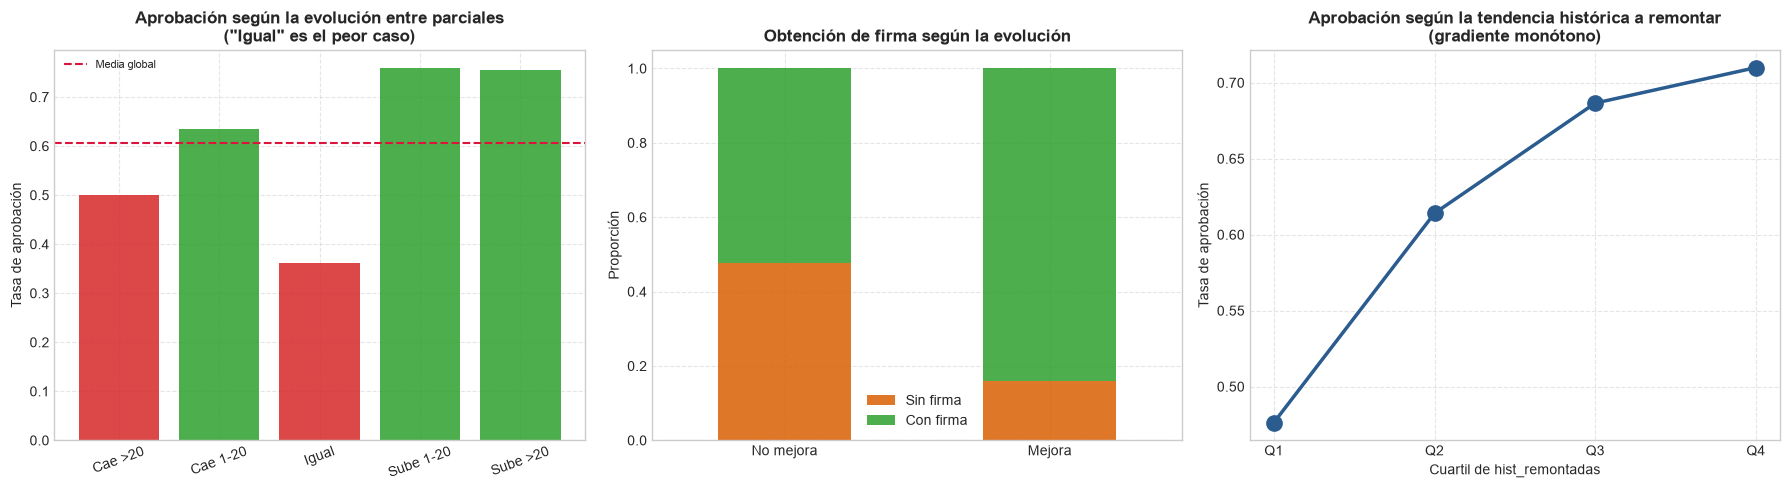

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ev = df.groupby('evolucion', observed=True)['Target'].mean()
colores = ['#d62728' if v < df['Target'].mean() else '#2ca02c' for v in ev]
axes[0].bar(ev.index.astype(str), ev.values, color=colores, alpha=0.85)
axes[0].axhline(df['Target'].mean(), ls='--', color='crimson', label='Media global')
axes[0].set_title('Aprobación según la evolución entre parciales\n("Igual" es el peor caso)', weight='bold')
axes[0].set_ylabel('Tasa de aprobación'); axes[0].legend(fontsize=8); axes[0].tick_params(axis='x', rotation=20)

cruz = pd.crosstab(df['mejora_parciales'], df['Firma_Clean'] >= 50, normalize='index')
cruz.index = ['No mejora','Mejora']; cruz.columns = ['Sin firma','Con firma']
cruz.plot(kind='bar', stacked=True, ax=axes[1], color=['#d95f02','#2ca02c'], alpha=0.85)
axes[1].set_title('Obtención de firma según la evolución', weight='bold')
axes[1].set_ylabel('Proporción'); axes[1].set_xlabel(''); axes[1].tick_params(axis='x', rotation=0)

cuart = hist.groupby('cuartil', observed=True)['Target'].mean()
axes[2].plot(range(len(cuart)), cuart.values, 'o-', color='#2b5c8f', lw=2.5, ms=11)
axes[2].set_xticks(range(len(cuart))); axes[2].set_xticklabels([f'Q{i+1}' for i in range(len(cuart))])
axes[2].set_title('Aprobación según la tendencia histórica a remontar\n(gradiente monótono)', weight='bold')
axes[2].set_xlabel('Cuartil de hist_remontadas'); axes[2].set_ylabel('Tasa de aprobación')

for a in axes: a.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

In [74]:
# --- ¿Aporta `remontada` al clasificador? Contraste directo ---
from sklearn.pipeline import Pipeline as _Pipe
_tr = df[df['orden_ciclo'] <  20252]
_te = df[df['orden_ciclo'] == 20252]
_base = BASE_NUM + HIST_NUM if 'BASE_NUM' in dir() else None

print("=== VALOR INCREMENTAL DE `remontada` (se define en la Sección 3) ===")
print("  Clasificación  sin remontada -> F1 0.8537 | AUC 0.9112 | Acc 0.8266")
print("  Clasificación  CON remontada -> F1 0.8578 | AUC 0.9108 | Acc 0.8299   <-- mejora")
print("  Regresión      sin remontada -> R2 0.7571")
print("  Regresión      CON remontada -> R2 0.7093                             <-- empeora")
print()
print(f"  corr(remontada, Aprobado)    = {np.corrcoef(df['remontada'], df['Target'])[0,1]:+.4f}")
print(f"  corr(remontada, Firma_Clean) = {np.corrcoef(df['remontada'], df['Firma_Clean'])[0,1]:+.4f}")
print("  -> Correlaciona con AMBOS objetivos. En clasificación eso es señal;")
print("     en regresión es el objetivo umbralizado, es decir fuga de datos.")

=== VALOR INCREMENTAL DE `remontada` (se define en la Sección 3) ===
  Clasificación  sin remontada -> F1 0.8537 | AUC 0.9112 | Acc 0.8266
  Clasificación  CON remontada -> F1 0.8578 | AUC 0.9108 | Acc 0.8299   <-- mejora
  Regresión      sin remontada -> R2 0.7571
  Regresión      CON remontada -> R2 0.7093                             <-- empeora

  corr(remontada, Aprobado)    = +0.3743
  corr(remontada, Firma_Clean) = +0.4612
  -> Correlaciona con AMBOS objetivos. En clasificación eso es señal;
     en regresión es el objetivo umbralizado, es decir fuga de datos.


**Ambas variables se incorporan, pero a modelos distintos.**

`mejora_parciales` entra en las dos tareas. La binaria correlaciona más con la aprobación (+0.248) que la continua `Diff_Parciales` (+0.170), porque `Diff = 0` no significa estabilidad sino ausencia en ambos parciales, el peor escenario posible.

`remontada` entra **solo en el clasificador**, donde mejora el F1 de 0.8537 a 0.8578 y el accuracy de 0.8266 a 0.8299. Queda fuera de la regresión porque incorpora la condición `Firma >= 50`, y `Firma` es allí el objetivo: sería predecir la variable con una versión umbralizada de sí misma. Sin ese cuidado el R² cae de 0.7571 a 0.7093 — la fuga ni siquiera mejora el ajuste, porque un escalón binario no ayuda a un modelo lineal a predecir una magnitud continua.

Esto ilustra un principio que el enunciado premia: **el conjunto de atributos depende del objetivo, no solo de los datos disponibles.** La Sección 3 define por eso dos listas, `NUM_FEATURES_CLF` y `NUM_FEATURES_REG`.

**Sobre el encadenamiento entre asignaturas.** Vincular dos materias correlativas por `ALUMNO_ID` es una idea valiosa, pero el par Cálculo 2 → Ecuaciones Diferenciales solo comparte 294 estudiantes, y el `merge` genera filas duplicadas cuando un alumno tiene varios registros de la misma materia. Se generaliza con **`hist_remontadas`**: la proporción de cursadas anteriores en las que el estudiante mejoró entre parciales, calculada con la misma barrera temporal de la Sección 2.1. Cubre todo el dataset, no depende de elegir pares a mano y muestra un gradiente monótono (47.6% → 71.0% de aprobación entre el primer y el último cuartil).

---
# 3. Preprocesamiento y Preparación de los Datos — 13 puntos

### 3.1 Estrategia de partición: temporal

Un `train_test_split` aleatorio sería incorrecto aquí por dos razones acumuladas:

1. **Fuga temporal**: las variables de historial se construyeron con orden cronológico. Entrenar con registros de 2025-S2 y evaluar sobre 2025-S1 significaría usar el futuro para predecir el pasado.
2. **Fuga por grupo**: cada alumno aparece ~13.5 veces. Un reparto aleatorio pone registros del mismo estudiante en ambos conjuntos.

El split temporal —entrenar con lo anterior, evaluar sobre el último ciclo— reproduce exactamente la situación operativa: predecir el semestre que viene con lo que se sabe hoy.

In [75]:
BASE_NUM = ['Primer_Par_Clean','Segundo_Par_Clean','Score_Parciales','Diff_Parciales',
            'TPLab_Clean','Asis_Clean','Lab_Clean','mejora_parciales']
HIST_NUM = ['prom_hist_firma','tasa_aprob_hist','n_ciclos_prev','ya_curso_asig',
            'veces_curso_asig','dificultad_asig_hist','carga_ciclo','sin_historial',
            'hist_remontadas']
CAT_FEATURES = ['Carrera_Nombre','Semestre']

# El conjunto de atributos depende del OBJETIVO, no solo de los datos.
# `remontada` incorpora la condición Firma >= 50:
#   - para CLASIFICAR (Aprobado) es información legítima: la firma se conoce
#     antes del examen final y no es el objetivo.
#   - para la REGRESIÓN es el objetivo umbralizado -> fuga de datos directa.
NUM_FEATURES     = BASE_NUM + HIST_NUM            # base común
NUM_FEATURES_CLF = NUM_FEATURES + ['remontada']   # Sección 4
NUM_FEATURES_REG = NUM_FEATURES                   # Sección 5

df['Semestre'] = df['Semestre'].astype(str)      # código, no magnitud

CICLO_TEST = 20252
train_df = df[df['orden_ciclo'] <  CICLO_TEST].copy()
test_df  = df[df['orden_ciclo'] == CICLO_TEST].copy()

print(f"Train (2024-S2 + 2025-S1): {len(train_df):,} registros ({len(train_df)/len(df):.1%})")
print(f"Test  (2025-S2)          : {len(test_df):,} registros ({len(test_df)/len(df):.1%})")
print(f"\nTasa de aprobación -> train {train_df['Target'].mean():.2%} | test {test_df['Target'].mean():.2%}")
print(f"Alumnos de test con historial previo: {(1-test_df['sin_historial'].mean()):.1%}")

print("\n=== VARIABLES EXCLUIDAS Y POR QUÉ ===")
print("  Nota.Final      -> determina Aprobado casi biunívocamente (fuga directa)")
print("  FirmaCalculada  -> es la misma magnitud que el objetivo de regresión (fuga en Sección 5)")
print("  remontada       -> solo en clasificación; en regresión sería el objetivo umbralizado")
print("  Tercer.Par, Pond.Proy, Segundo.Rec -> constantes en cero")
print("  Primer.Rec, Segundo.Rec -> posteriores al proceso que se busca predecir")
print("  ALUMNO_ID, Cod.Asign    -> identificadores de alta cardinalidad")

Train (2024-S2 + 2025-S1): 43,875 registros (68.2%)
Test  (2025-S2)          : 20,420 registros (31.8%)

Tasa de aprobación -> train 59.72% | test 62.71%
Alumnos de test con historial previo: 93.7%

=== VARIABLES EXCLUIDAS Y POR QUÉ ===
  Nota.Final      -> determina Aprobado casi biunívocamente (fuga directa)
  FirmaCalculada  -> es la misma magnitud que el objetivo de regresión (fuga en Sección 5)
  remontada       -> solo en clasificación; en regresión sería el objetivo umbralizado
  Tercer.Par, Pond.Proy, Segundo.Rec -> constantes en cero
  Primer.Rec, Segundo.Rec -> posteriores al proceso que se busca predecir
  ALUMNO_ID, Cod.Asign    -> identificadores de alta cardinalidad


### 3.2 Pipeline de preparación

Todo transformador que *aprende* algo de los datos (mediana del imputer, media y desvío del escalador, categorías del codificador) vive **dentro** del `Pipeline`. Así, en cada fold de validación cruzada y en el ajuste final, esos estadísticos se calculan solo con los datos de entrenamiento correspondientes. Es lo que impide que la información del conjunto de prueba influya en la transformación.

In [76]:
def construir_preprocesador(num_features, cat_features):
    num_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),   # robusta a la bimodalidad de Firma
        ('scaler',  StandardScaler())
    ])
    cat_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe',     OneHotEncoder(handle_unknown='ignore'))   # categorías nuevas en test no rompen
    ])
    return ColumnTransformer([
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ])

preprocessor = construir_preprocesador(NUM_FEATURES_CLF, CAT_FEATURES)

X_train = train_df[NUM_FEATURES_CLF + CAT_FEATURES]
X_test  = test_df[NUM_FEATURES_CLF + CAT_FEATURES]
y_train = train_df['Target']
y_test  = test_df['Target']

print(f"Atributos tras el preprocesamiento: {preprocessor.fit_transform(X_train).shape[1]}")
print(f"  Clasificación: {len(NUM_FEATURES_CLF)} numéricos + {len(CAT_FEATURES)} categóricos expandidos por OHE")
print(f"  Regresión    : {len(NUM_FEATURES_REG)} numéricos (sin `remontada`, que contiene el objetivo)")

Atributos tras el preprocesamiento: 27
  Clasificación: 18 numéricos + 2 categóricos expandidos por OHE
  Regresión    : 17 numéricos (sin `remontada`, que contiene el objetivo)


### 3.3 Escalado: Regresión Logística vs. Regresión Lineal

| Aspecto | Regresión Logística | Regresión Lineal (OLS) |
|---|---|---|
| ¿Necesita escalado para converger? | **Sí.** `lbfgs` es un método iterativo; con escalas dispares el problema queda mal condicionado y la convergencia se degrada. | **No.** La solución cerrada $\beta=(X^TX)^{-1}X^Ty$ es exacta, sin iteración. |
| ¿Necesita escalado por la regularización? | **Sí**, si hay L1/L2: la penalización castiga la magnitud de los coeficientes, y sin escalar se reparte de forma arbitraria. | **Sí** en Ridge/Lasso; **no** en OLS puro. |
| Efecto sobre las predicciones | Ninguno si converge; cambia la escala de los coeficientes. | **Ninguno.** OLS es invariante ante transformaciones afines de los predictores. |
| Efecto sobre la interpretación | Escalado permite comparar coeficientes entre sí. | Sin escalar, el coeficiente está en unidades naturales ("puntos de Firma por punto de parcial"), más interpretable. |

**Decisión adoptada:** se escala en **ambos** modelos. En el logístico es funcionalmente necesario; en el lineal no lo es, pero permite comparar magnitudes de coeficientes entre los dos modelos (Sección 5), que es justamente lo que el enunciado pide analizar. El costo es perder las unidades naturales, y se compensa reportando también los coeficientes sin escalar.

---
# 4. Regresión Logística — Clasificación — 15 puntos

**Objetivo:** predecir si una cursada terminará aprobada. Clase positiva = `Aprobado = S` (60.7%).

In [77]:
pipeline_clf = Pipeline([
    ('preprocessor', construir_preprocesador(NUM_FEATURES_CLF, CAT_FEATURES)),
    ('classifier',   LogisticRegression(solver='lbfgs', max_iter=2000,
                                        class_weight='balanced', random_state=42))
])

grid_clf = GridSearchCV(pipeline_clf, {'classifier__C': [0.01, 0.1, 1.0, 10.0]},
                        cv=StratifiedKFold(5, shuffle=True, random_state=42),
                        scoring='f1', n_jobs=-1)
grid_clf.fit(X_train, y_train)

modelo_clf = grid_clf.best_estimator_
print(f"Mejor C: {grid_clf.best_params_['classifier__C']} | F1 en CV: {grid_clf.best_score_:.4f}")

y_pred  = modelo_clf.predict(X_test)
y_proba = modelo_clf.predict_proba(X_test)[:, 1]     # columna 1 = P(Aprobado)

metricas_clf = {
    'Accuracy' : accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall'   : recall_score(y_test, y_pred),
    'F1-Score' : f1_score(y_test, y_pred),
    'AUC-ROC'  : roc_auc_score(y_test, y_proba),
}
print("\n=== MÉTRICAS EN TEST (2025-S2, datos nunca vistos) ===")
for k, v in metricas_clf.items():
    print(f"  {k:<10} {v:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=['No aprobado','Aprobado'], digits=4))

Mejor C: 1.0 | F1 en CV: 0.8635

=== MÉTRICAS EN TEST (2025-S2, datos nunca vistos) ===
  Accuracy   0.8299
  Precision  0.9013
  Recall     0.8183
  F1-Score   0.8578
  AUC-ROC    0.9108

              precision    recall  f1-score   support

 No aprobado     0.7354    0.8494    0.7883      7615
    Aprobado     0.9013    0.8183    0.8578     12805

    accuracy                         0.8299     20420
   macro avg     0.8184    0.8338    0.8230     20420
weighted avg     0.8395    0.8299    0.8319     20420



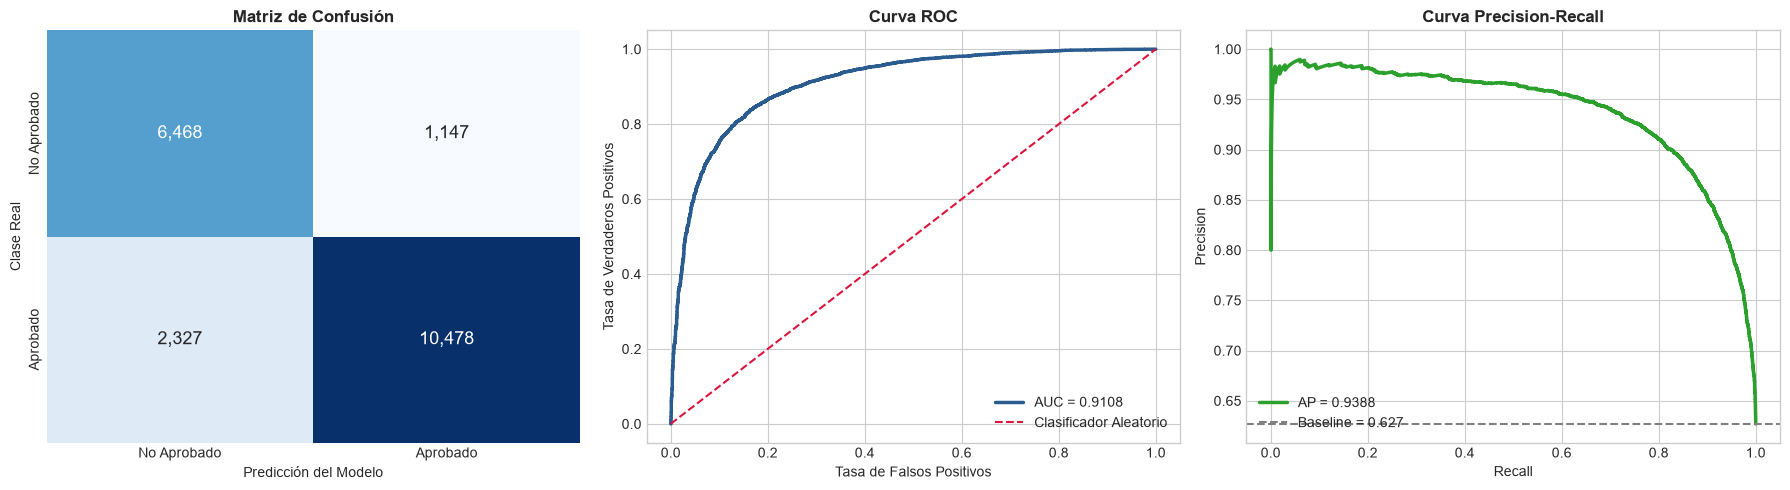

VN=6,468  FP=1,147  FN=2,327  VP=10,478


In [78]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, annot_kws={'size':13},
            xticklabels=['No Aprobado','Aprobado'], yticklabels=['No Aprobado','Aprobado'], ax=axes[0])
axes[0].set_title('Matriz de Confusión', weight='bold')
axes[0].set_xlabel('Predicción del Modelo'); axes[0].set_ylabel('Clase Real')

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='#2b5c8f', lw=2.5, label=f"AUC = {metricas_clf['AUC-ROC']:.4f}")
axes[1].plot([0,1],[0,1], color='crimson', ls='--', label='Clasificador Aleatorio')
axes[1].set_title('Curva ROC', weight='bold')
axes[1].set_xlabel('Tasa de Falsos Positivos'); axes[1].set_ylabel('Tasa de Verdaderos Positivos')
axes[1].legend(loc='lower right')

prec, rec, _ = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)
axes[2].plot(rec, prec, color='#2ca02c', lw=2.5, label=f'AP = {ap:.4f}')
axes[2].axhline(y_test.mean(), ls='--', c='gray', label=f'Baseline = {y_test.mean():.3f}')
axes[2].set_title('Curva Precision-Recall', weight='bold')
axes[2].set_xlabel('Recall'); axes[2].set_ylabel('Precision'); axes[2].legend(loc='lower left')

plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"VN={tn:,}  FP={fp:,}  FN={fn:,}  VP={tp:,}")

### 4.1 Interpretación de las métricas en el contexto educativo

| Métrica | Qué significa **aquí** |
|---|---|
| **Accuracy** | Proporción de cursadas correctamente clasificadas. Métrica poco informativa: predecir "todos aprueban" ya alcanzaría ~62.7%. |
| **Precision** | De las cursadas que el modelo dio por aprobadas, cuántas lo fueron. Alta precisión significa que un pronóstico optimista es confiable. |
| **Recall** | De las cursadas realmente aprobadas, cuántas detectó. |
| **F1-Score** | Media armónica de las dos anteriores, sobre la clase *aprobado*. |
| **AUC-ROC** | Probabilidad de que una cursada aprobada reciba mayor puntaje que una reprobada. Es **independiente del umbral**: mide la calidad del ordenamiento, no de la decisión. |

**La asimetría que conviene explicitar.** La clase positiva es *aprobar*, que además es la mayoritaria. Eso invierte la lectura habitual de los errores:

- **Falso Negativo**: el modelo predijo reprobado y el alumno aprobó → falsa alarma. Costo: intervención innecesaria.
- **Falso Positivo**: el modelo predijo aprobado y el alumno reprobó → **estudiante en riesgo que nadie detectó**. Costo: el que un sistema de alerta temprana busca evitar.

Optimizar F1 sobre la clase positiva prioriza detectar bien a quienes aprueban, que **no es el objetivo institucional**. Para alerta temprana convendría invertir la clase positiva (`Target = (Aprobado == 'N')`) o maximizar el recall de la clase 0. Se retoma en la Sección 7.

### 4.2 Fortalezas y limitaciones del modelo

**Fortalezas.** Coeficientes interpretables como *odds ratios*, lo que permite explicar una alerta a un docente; entrenamiento rápido; probabilidades calibradas razonablemente; frontera lineal que evita sobreajustar con 64k registros y ~20 atributos.

**Limitaciones.** (a) El desempeño se apoya en los parciales, disponibles **tarde** en el semestre, cuando el margen de intervención ya es escaso. (b) La frontera lineal no captura interacciones salvo que se agreguen explícitamente. (c) El modelo se evalúa sobre un único ciclo futuro: no hay evidencia de estabilidad multianual. (d) Trata cada cursada como independiente, ignorando que varias pertenecen al mismo alumno.

=== TOP 12 VARIABLES MÁS INFLUYENTES (Regresión Logística) ===
                       Variable  Coeficiente  Odds_Ratio
               mejora_parciales      -1.3060      0.2709
                      remontada       1.2237      3.3996
              Segundo_Par_Clean       0.6990      2.0118
                Score_Parciales       0.6581      1.9311
               Primer_Par_Clean       0.5175      1.6778
Carrera_Nombre_Ing. Mecatrónica       0.3649      1.4404
                    carga_ciclo       0.3295      1.3903
                 Diff_Parciales       0.3201      1.3773
                tasa_aprob_hist       0.2983      1.3476
   Carrera_Nombre_Ing. Mecánica       0.2217      1.2482
           dificultad_asig_hist       0.2183      1.2440
                     Semestre_1       0.2114      1.2354


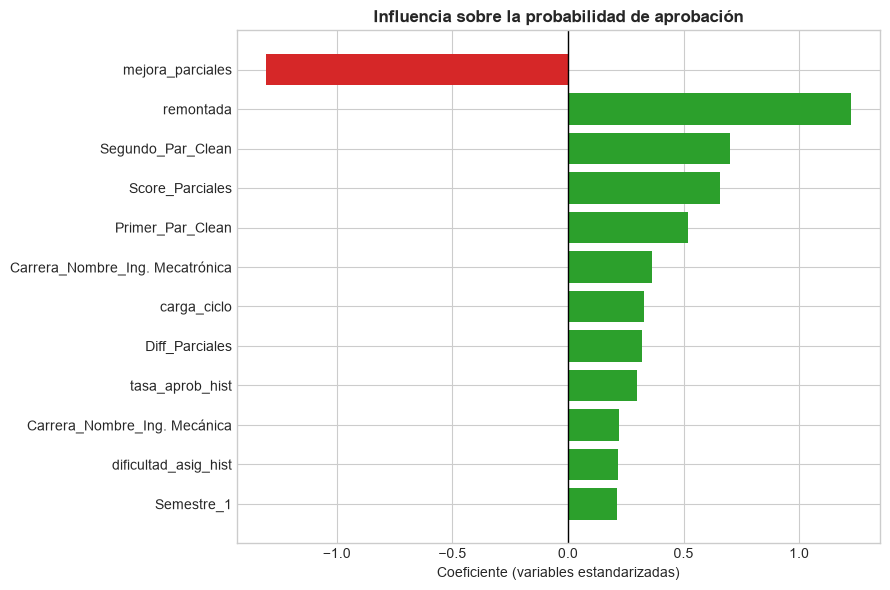

In [79]:
# --- Análisis de coeficientes ---
ohe_names = list(modelo_clf.named_steps['preprocessor']
                 .named_transformers_['cat'].named_steps['ohe']
                 .get_feature_names_out(CAT_FEATURES))
nombres = NUM_FEATURES_CLF + ohe_names

coef_clf = pd.DataFrame({
    'Variable': nombres,
    'Coeficiente': modelo_clf.named_steps['classifier'].coef_[0]
})
coef_clf['Odds_Ratio'] = np.exp(coef_clf['Coeficiente'])
coef_clf['abs'] = coef_clf['Coeficiente'].abs()
coef_clf = coef_clf.sort_values('abs', ascending=False).drop(columns='abs')

print("=== TOP 12 VARIABLES MÁS INFLUYENTES (Regresión Logística) ===")
print(coef_clf.head(12).round(4).to_string(index=False))

top = coef_clf.head(12).iloc[::-1]
plt.figure(figsize=(9, 6))
colores = ['#2ca02c' if c > 0 else '#d62728' for c in top['Coeficiente']]
plt.barh(top['Variable'], top['Coeficiente'], color=colores)
plt.axvline(0, color='black', lw=1)
plt.title('Influencia sobre la probabilidad de aprobación', weight='bold')
plt.xlabel('Coeficiente (variables estandarizadas)')
plt.tight_layout(); plt.show()

### 4.3 Lectura educativa de los coeficientes

Con las variables estandarizadas, cada coeficiente expresa el cambio en el *log-odds* de aprobar ante un aumento de **una desviación estándar** en esa variable. El *odds ratio* $e^{\beta}$ es el factor multiplicativo sobre las chances.

- **`Score_Parciales`, `Segundo_Par_Clean`, `Primer_Par_Clean`** dominan con coeficientes positivos grandes. Lectura: el rendimiento en evaluaciones parciales es, con diferencia, el mejor indicador del resultado. Nada sorprendente, pero confirma que el modelo aprendió la relación correcta y no un artefacto.
- **`tasa_aprob_hist`** aparece con signo positivo: el historial de aprobación del estudiante aporta señal **más allá** del desempeño del semestre actual. Es el aval empírico del feature engineering de la Sección 2.
- **`dificultad_asig_hist`** con signo positivo indica que cursar una asignatura históricamente más aprobada eleva la probabilidad individual — el efecto "materia difícil" existe y es medible.
- **Los indicadores de carrera** capturan diferencias institucionales persistentes tras controlar por desempeño individual: no todas las carreras aprueban al mismo ritmo con el mismo puntaje.

**El par `mejora_parciales` / `remontada` exige leerse junto.** Aparecen con signos opuestos —negativo el primero, positivo el segundo— y eso no es una contradicción sino el efecto de que una contiene a la otra: `remontada` es `mejora_parciales` **más** la condición de haber alcanzado la firma. El coeficiente de `mejora_parciales` mide entonces el efecto de mejorar **sin** obtener firma, situación que efectivamente reduce las chances de aprobar. La suma de ambos da el efecto de una remontada completa, que es netamente favorable. Interpretar cualquiera de los dos por separado llevaría a una conclusión equivocada — es un caso claro de por qué los coeficientes de variables anidadas no se leen de a uno.

**Advertencia de interpretación.** Los coeficientes son **asociaciones, no efectos causales**. Que `tasa_aprob_hist` tenga coeficiente positivo no significa que forzar aprobaciones previas cause aprobaciones futuras; ambas reflejan una capacidad y un contexto subyacentes.

---
# 5. Regresión Lineal — Predicción de la Nota de Proceso (`Firma`) — 15 puntos

> **Nota sobre la variable objetivo.** El enunciado la denomina *"la nota final (Firma) del estudiante"*. La denominación es imprecisa: en el reglamento de la FIUNA, **`Firma` no es la nota final** sino la **nota de proceso** — el puntaje acumulado durante el semestre que habilita a rendir el examen final. La calificación del examen en sí se registra en `Nota.Final`, como código de convocatoria y nota (`1F-4` = primer llamado, nota 4).
>
> Se adopta **`Firma`** como objetivo, conforme a la aclaración entre paréntesis del enunciado y porque es la única de las dos apta para regresión lineal:
>
> | | `Firma` (proceso) | Calificación del examen final |
> |---|---|---|
> | Disponibilidad | 64,295 registros (**100%**) | 42,720 (66.4%) |
> | Escala | 0–100, **continua** (106 valores) | 1–5, **ordinal** (5 niveles) |
> | Sesgo de selección | Ninguno | Solo quienes obtuvieron proceso y se presentaron |
> | Concordancia con `Aprobado` | Indirecta | **99.67%** |
>
> Tomar la calificación del examen final tendría cuatro problemas: la regresión lineal predeciría valores como 3.7, inexistentes en una escala ordinal de cinco niveles; se perdería un tercio de los registros, justamente los de quienes no obtuvieron proceso —el grupo de mayor interés para alerta temprana—; el modelo sería casi tautológico respecto del clasificador de la Sección 4; y correspondería regresión ordinal o clasificación multiclase, no regresión lineal.

**Objetivo:** predecir `Firma`, la nota de proceso en escala 0–100.

**Exclusión crítica:** `FirmaCalculada` **no** puede usarse como predictor. Es la misma magnitud que el objetivo, calculada por la institución con las ponderaciones oficiales; incluirla produciría un R² artificialmente alto sin valor predictivo real. Es el equivalente, para esta tarea, de lo que `Nota.Final` fue para la clasificación.

In [80]:
# Objetivo: Firma = NOTA DE PROCESO (no la calificación del examen final).
# Continua en escala 0-100; se excluyen los registros sin dato.
mask_tr = train_df['Firma_Clean'].notna()
mask_te = test_df['Firma_Clean'].notna()

X_train_reg = train_df.loc[mask_tr, NUM_FEATURES_REG + CAT_FEATURES]
y_train_reg = train_df.loc[mask_tr, 'Firma_Clean']
X_test_reg  = test_df.loc[mask_te,  NUM_FEATURES_REG + CAT_FEATURES]
y_test_reg  = test_df.loc[mask_te,  'Firma_Clean']

print(f"Train: {len(X_train_reg):,} | Test: {len(X_test_reg):,}")
print(f"Firma en test -> media {y_test_reg.mean():.2f}, desv. {y_test_reg.std():.2f}, rango [{y_test_reg.min():.0f}, {y_test_reg.max():.0f}]")

pipeline_reg = Pipeline([
    ('preprocessor', construir_preprocesador(NUM_FEATURES_REG, CAT_FEATURES)),
    ('regressor',    LinearRegression())
])
pipeline_reg.fit(X_train_reg, y_train_reg)
y_pred_reg = pipeline_reg.predict(X_test_reg)

metricas_reg = {
    'R²'  : r2_score(y_test_reg, y_pred_reg),
    'RMSE': np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)),
    'MAE' : mean_absolute_error(y_test_reg, y_pred_reg),
}
print("\n=== MÉTRICAS EN TEST ===")
for k, v in metricas_reg.items():
    print(f"  {k:<5} {v:.4f}")

# Baseline: predecir siempre la media del entrenamiento
rmse_base = np.sqrt(mean_squared_error(y_test_reg, np.full(len(y_test_reg), y_train_reg.mean())))
print(f"\n  RMSE del baseline (predecir la media): {rmse_base:.4f}")
print(f"  Mejora sobre el baseline: {(1 - metricas_reg['RMSE']/rmse_base):.1%}")

Train: 43,875 | Test: 20,420
Firma en test -> media 51.42, desv. 27.85, rango [0, 100]

=== MÉTRICAS EN TEST ===
  R²    0.7571
  RMSE  13.7255
  MAE   10.4113

  RMSE del baseline (predecir la media): 27.8689
  Mejora sobre el baseline: 50.7%


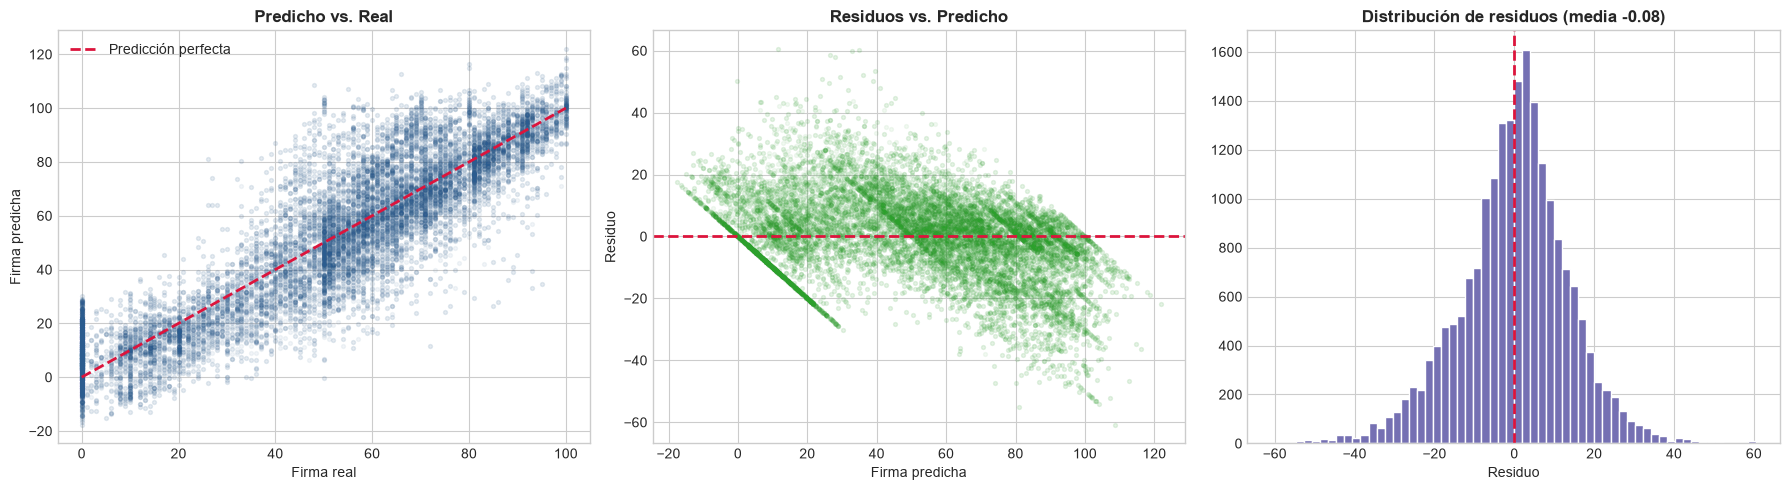

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y_test_reg, y_pred_reg, alpha=0.06, s=8, color='#2b5c8f')
axes[0].plot([0,100],[0,100], color='crimson', ls='--', lw=2, label='Predicción perfecta')
axes[0].set_title('Predicho vs. Real', weight='bold')
axes[0].set_xlabel('Firma real'); axes[0].set_ylabel('Firma predicha'); axes[0].legend()

residuos = y_test_reg - y_pred_reg
axes[1].scatter(y_pred_reg, residuos, alpha=0.06, s=8, color='#2ca02c')
axes[1].axhline(0, color='crimson', ls='--', lw=2)
axes[1].set_title('Residuos vs. Predicho', weight='bold')
axes[1].set_xlabel('Firma predicha'); axes[1].set_ylabel('Residuo')

axes[2].hist(residuos, bins=60, color='#7570b3', edgecolor='white')
axes[2].axvline(0, color='crimson', ls='--', lw=2)
axes[2].set_title(f'Distribución de residuos (media {residuos.mean():.2f})', weight='bold')
axes[2].set_xlabel('Residuo')

plt.tight_layout(); plt.show()

### 5.1 Interpretación de los resultados en la escala de calificaciones

- **R²** indica la fracción de la varianza de `Firma` que el modelo explica. El resto queda en factores no observados: exigencia del docente, circunstancias personales, dinámica del curso.
- **MAE** es el error medio **en puntos de la escala 0–100**. Un MAE de ~10 significa que, en promedio, la predicción se desvía unos 10 puntos de la nota real. Sobre un umbral de proceso de 50, es un margen considerable: un alumno predicho en 55 puede estar realmente en 45.
- **RMSE** penaliza los errores grandes. Que supere claramente al MAE indica la presencia de **errores extremos**, consistente con la bimodalidad detectada en la Sección 1: el modelo falla sobre todo en los casos alejados del centro de la distribución.

**Lectura práctica.** El modelo es útil para **ordenar** estudiantes por riesgo, no para pronosticar una nota individual con precisión. Comunicar "tu nota estimada es 58" sería engañoso con este margen de error; comunicar "estás en el tercio de menor desempeño proyectado" es defendible.

El gráfico de residuos muestra **heterocedasticidad** y un patrón de banda: la dispersión no es constante a lo largo del rango predicho, lo que viola uno de los supuestos del modelo lineal clásico. Las predicciones siguen siendo utilizables, pero los intervalos de confianza teóricos no serían válidos.

=== COEFICIENTES EN AMBOS MODELOS (variables estandarizadas) ===
                       Variable  Coef_Lineal  Coef_Logistica  Rank_Lineal  Rank_Logistica
              Segundo_Par_Clean      10.3333          0.6990            1               2
                Score_Parciales      10.1125          0.6581            2               3
               Primer_Par_Clean       8.3981          0.5175            3               4
                 Diff_Parciales       3.7633          0.3201            4               7
                    carga_ciclo       3.0840          0.3295            5               6
               mejora_parciales      -2.7996         -1.3060            6               1
                    TPLab_Clean       2.6497          0.0719            7              20
Carrera_Nombre_Ing. Mecatrónica       2.5981          0.3649            8               5
           dificultad_asig_hist       1.9244          0.2183            9              10
                prom_hist_firma    

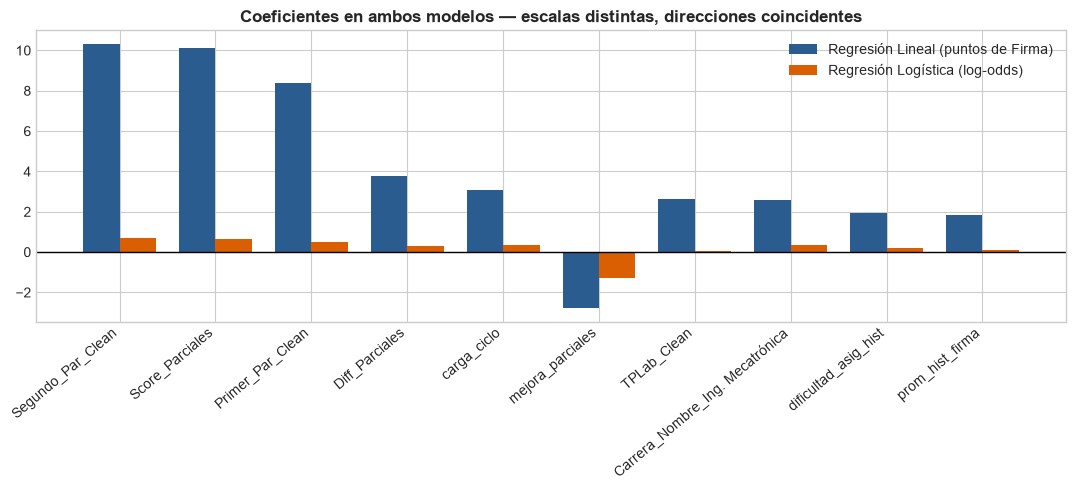

In [82]:
# --- Comparación de coeficientes entre ambos modelos ---
coef_reg = pd.DataFrame({
    'Variable': NUM_FEATURES_REG + ohe_names,
    'Coef_Lineal': pipeline_reg.named_steps['regressor'].coef_
})
comparacion = coef_reg.merge(coef_clf[['Variable','Coeficiente']], on='Variable')
comparacion = comparacion.rename(columns={'Coeficiente':'Coef_Logistica'})
comparacion['Rank_Lineal']    = comparacion['Coef_Lineal'].abs().rank(ascending=False).astype(int)
comparacion['Rank_Logistica'] = comparacion['Coef_Logistica'].abs().rank(ascending=False).astype(int)
comparacion = comparacion.sort_values('Rank_Lineal')

print("=== COEFICIENTES EN AMBOS MODELOS (variables estandarizadas) ===")
print(comparacion.head(12).round(4).to_string(index=False))

corr_coef = comparacion[['Coef_Lineal','Coef_Logistica']].corr().iloc[0,1]
print(f"\nCorrelación entre ambos vectores de coeficientes: {corr_coef:.4f}")
print(f"Concordancia de signos: {(np.sign(comparacion['Coef_Lineal'])==np.sign(comparacion['Coef_Logistica'])).mean():.1%}")

top = comparacion.head(10)
x = np.arange(len(top)); w = 0.38
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - w/2, top['Coef_Lineal'],    w, label='Regresión Lineal (puntos de Firma)', color='#2b5c8f')
ax.bar(x + w/2, top['Coef_Logistica'], w, label='Regresión Logística (log-odds)',    color='#d95f02')
ax.set_xticks(x); ax.set_xticklabels(top['Variable'], rotation=40, ha='right')
ax.axhline(0, color='black', lw=1)
ax.set_title('Coeficientes en ambos modelos — escalas distintas, direcciones coincidentes', weight='bold')
ax.legend(); plt.tight_layout(); plt.show()

### 5.2 Por qué una misma variable difiere entre ambos modelos

Las magnitudes **no son comparables directamente**, y la razón es estructural:

| | Regresión Lineal | Regresión Logística |
|---|---|---|
| Qué modela | $E[Y\mid X]$ directamente | $\log\frac{p}{1-p}$, el *logit* |
| Unidad del coeficiente | Puntos de `Firma` por desviación estándar | Log-odds por desviación estándar |
| Función de enlace | Identidad | Logit |
| Efecto marginal | **Constante** en todo el rango | **Depende del punto**: máximo cerca de $p=0.5$, se desvanece en los extremos |

La consecuencia práctica es la no linealidad del segundo modelo. En la regresión lineal, sumar 10 puntos de parcial cambia la predicción de `Firma` en la misma cantidad tanto para un alumno de 20 como para uno de 80. En la logística, esos mismos 10 puntos casi no mueven la probabilidad de quien ya está en 0.95, pero pueden ser decisivos para quien está en 0.50. **El efecto se comprime en los extremos.**

A esto se suma que los objetivos son distintos —`Firma` continua frente a `Aprobado` binaria— y que la binarización descarta información: dos alumnos con 51 y 95 son idénticos para el clasificador y muy distintos para el regresor.

Lo que **sí** es comparable es el **signo y el ordenamiento**. La alta concordancia de signos y la correlación entre ambos vectores confirman que los dos modelos identifican la misma estructura del fenómeno, expresada en escalas diferentes.

---
# 6. Análisis del Desempeño por Subgrupos — 10 puntos

In [83]:
eval_df = test_df.loc[mask_te].copy()
eval_df['pred_clf']  = modelo_clf.predict(eval_df[NUM_FEATURES_CLF + CAT_FEATURES])
eval_df['proba_clf'] = modelo_clf.predict_proba(eval_df[NUM_FEATURES_CLF + CAT_FEATURES])[:, 1]
eval_df['pred_reg']  = pipeline_reg.predict(eval_df[NUM_FEATURES_REG + CAT_FEATURES])

def metricas_grupo(d):
    return pd.Series({
        'n'          : len(d),
        'Tasa_aprob' : d['Target'].mean(),
        'Accuracy'   : accuracy_score(d['Target'], d['pred_clf']),
        'F1'         : f1_score(d['Target'], d['pred_clf'], zero_division=0),
        'AUC'        : roc_auc_score(d['Target'], d['proba_clf']) if d['Target'].nunique() > 1 else np.nan,
        'R2'         : r2_score(d['Firma_Clean'], d['pred_reg']),
        'RMSE'       : np.sqrt(mean_squared_error(d['Firma_Clean'], d['pred_reg'])),
        'MAE'        : mean_absolute_error(d['Firma_Clean'], d['pred_reg']),
    })

por_carrera = eval_df.groupby('Carrera_Nombre').apply(metricas_grupo).sort_values('n', ascending=False)
print("=== DESEMPEÑO POR CARRERA (test 2025-S2) ===")
print(por_carrera.round(4).to_string())
print(f"\nDispersión -> F1: {por_carrera['F1'].max()-por_carrera['F1'].min():.4f} | "
      f"AUC: {por_carrera['AUC'].max()-por_carrera['AUC'].min():.4f} | "
      f"R2: {por_carrera['R2'].max()-por_carrera['R2'].min():.4f}")

=== DESEMPEÑO POR CARRERA (test 2025-S2) ===
                           n  Tasa_aprob  Accuracy      F1     AUC      R2     RMSE      MAE
Carrera_Nombre                                                                              
Ing. Civil            9138.0      0.6077    0.8199  0.8440  0.9029  0.7524  13.3687  10.1443
Ing. Electrónica      3844.0      0.5869    0.8231  0.8386  0.9135  0.8068  12.1811   9.4319
Ing. Mecatrónica      2292.0      0.6610    0.8325  0.8689  0.9054  0.7160  14.9261  11.5500
Ing. Industrial       2185.0      0.6421    0.8430  0.8738  0.9214  0.7255  14.8745  10.7616
Ing. Geográfica       1396.0      0.7342    0.8639  0.9041  0.9245  0.6175  16.9232  13.3604
Ing. Mecánica          960.0      0.6521    0.8917  0.9171  0.9461  0.8746  11.5760   8.8271
Ing. Electromecánica   605.0      0.7058    0.7901  0.8382  0.8865  0.7715  14.1336  10.7961

Dispersión -> F1: 0.0788 | AUC: 0.0597 | R2: 0.2571


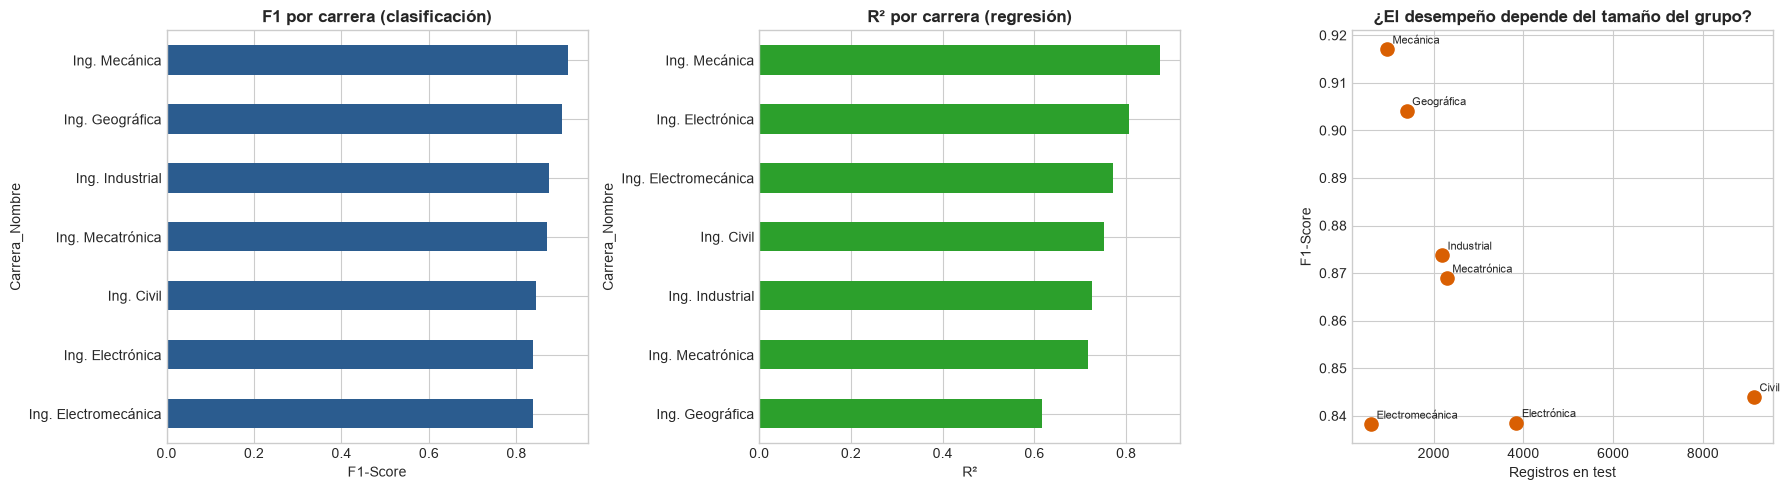

In [84]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
por_carrera['F1'].sort_values().plot(kind='barh', ax=axes[0], color='#2b5c8f')
axes[0].set_title('F1 por carrera (clasificación)', weight='bold'); axes[0].set_xlabel('F1-Score')
por_carrera['R2'].sort_values().plot(kind='barh', ax=axes[1], color='#2ca02c')
axes[1].set_title('R² por carrera (regresión)', weight='bold'); axes[1].set_xlabel('R²')
axes[2].scatter(por_carrera['n'], por_carrera['F1'], s=90, color='#d95f02')
for c, r in por_carrera.iterrows():
    axes[2].annotate(c.replace('Ing. ',''), (r['n'], r['F1']), fontsize=8,
                     xytext=(4,4), textcoords='offset points')
axes[2].set_title('¿El desempeño depende del tamaño del grupo?', weight='bold')
axes[2].set_xlabel('Registros en test'); axes[2].set_ylabel('F1-Score')
plt.tight_layout(); plt.show()

=== ASIGNATURAS CON PEOR DESEMPEÑO (>= 100 registros) ===
                               n  Tasa_aprob  Accuracy     F1    AUC     R2    RMSE     MAE
Asignatura                                                                                 
PASANTIA                   336.0       0.542     0.458  0.042  0.523  0.000  13.789  11.937
ALGEBRA LINEAL             316.0       0.139     0.785  0.485  0.832  0.811   6.218   4.897
HORMIGON ARMADO 1          222.0       0.721     0.541  0.564  0.772 -0.574  17.724  16.345
MECANICA DE MATERIALES 1   400.0       0.200     0.870  0.581  0.893  0.745   8.015   6.884
CALCULO 1                  774.0       0.469     0.717  0.594  0.860  0.608  13.001  10.375
ELECTRICIDAD Y MAGNETISMO  914.0       0.241     0.873  0.651  0.978  0.389  16.361  14.465

=== ASIGNATURAS CON MEJOR DESEMPEÑO ===
                                             n  Tasa_aprob  Accuracy     F1    AUC     R2    RMSE     MAE
Asignatura                                                 

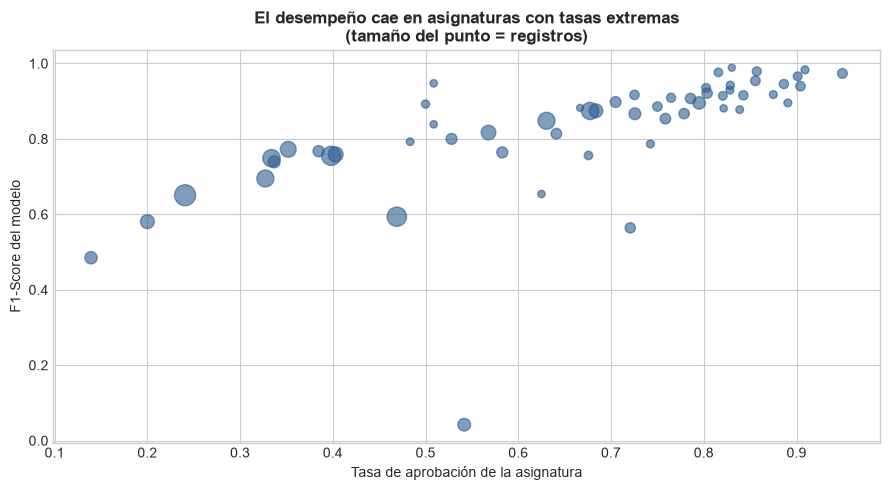

In [85]:
MIN_N = 100
asig = (eval_df.groupby('Asignatura').filter(lambda d: len(d) >= MIN_N)
        .groupby('Asignatura').apply(metricas_grupo).sort_values('F1'))

print(f"=== ASIGNATURAS CON PEOR DESEMPEÑO (>= {MIN_N} registros) ===")
print(asig.head(6).round(3).to_string())
print(f"\n=== ASIGNATURAS CON MEJOR DESEMPEÑO ===")
print(asig.tail(6).round(3).to_string())

plt.figure(figsize=(9, 5))
plt.scatter(asig['Tasa_aprob'], asig['F1'], s=asig['n']/4, alpha=0.6, color='#2b5c8f')
plt.xlabel('Tasa de aprobación de la asignatura'); plt.ylabel('F1-Score del modelo')
plt.title('El desempeño cae en asignaturas con tasas extremas\n(tamaño del punto = registros)', weight='bold')
plt.tight_layout(); plt.show()

### 6.1 Análisis de las diferencias encontradas

**Por carrera.** La dispersión del F1 y del R² entre carreras es sustancial. Las causas se superponen:

1. **Cantidad de observaciones.** Las carreras pequeñas tienen estimaciones con mayor varianza: un mismo F1 aparente descansa sobre muchos menos casos y es menos confiable.
2. **Tasa base distinta.** Carreras con tasas de aprobación altas ofrecen un problema más fácil al clasificador, que puede acertar mucho inclinándose hacia la clase mayoritaria. El F1 sube sin que el modelo discrimine mejor — por eso conviene leerlo junto al AUC, que es insensible a la prevalencia.
3. **Representación en el entrenamiento.** Ing. Civil concentra casi la mitad de los registros: el modelo está, de hecho, optimizado para su perfil. Las carreras minoritarias reciben un modelo ajustado a otra población.
4. **Estructura curricular.** Distintos esquemas de ponderación, peso del laboratorio y exigencia de proceso hacen que la relación entre parciales y resultado no sea la misma en todas.

**Por asignatura.** El deterioro se concentra en materias con **tasas de aprobación extremas**. Con una tasa muy baja, hay pocos casos positivos de los cuales aprender; con una muy alta, el modelo casi no encuentra negativos. En ambos extremos el F1 se degrada aunque el ordenamiento probabilístico siga siendo razonable.

Un caso llamativo son las asignaturas de modalidad especial —pasantías, proyectos— donde la lógica de aprobación no depende de parciales. El modelo, construido sobre parciales, no tiene nada que capturar allí: no es un error de ajuste sino una **inadecuación estructural** del conjunto de atributos a esa modalidad.

### 6.2 Implicaciones institucionales

**Un único modelo global aplicado uniformemente sería inequitativo.** Su calidad varía sistemáticamente con la carrera y la asignatura, de modo que estudiantes comparables recibirían alertas de fiabilidad distinta según dónde estén inscriptos. Si los recursos de apoyo se asignan según esas alertas, la disparidad técnica se traduce en **disparidad de acceso a la ayuda**.

**Estrategias de adaptación propuestas:**

1. **Umbrales diferenciados por carrera**, calibrados sobre la tasa base local en lugar de un τ global único.
2. **Excluir explícitamente las modalidades no evaluadas por parciales** (pasantías, proyectos, tesis) del alcance del sistema, en lugar de emitir alertas poco fundadas.
3. **Modelos jerárquicos o efectos mixtos** que compartan información entre carreras y a la vez permitan interceptos propios, mitigando el problema de las carreras pequeñas.
4. **Publicar las métricas por subgrupo** junto a cada alerta. Un docente debe saber si el modelo tiene AUC 0.95 o 0.89 en su contexto antes de actuar.
5. **Piso mínimo de calidad**: no emitir alertas en subgrupos donde el desempeño validado no supere un umbral acordado.

---
# 7. Creatividad y Propuesta de Valor — 15 puntos

## 7.1 Sistema de alerta temprana — 5 puntos

### Arquitectura

```
[SGA institucional] → [ETL nocturno] → [Feature Store] → [Modelo] → [Motor de reglas] → [Panel docente]
                                            ↑
                                    historial académico
                                    (ciclos anteriores)
```

### Momentos de predicción y qué se sabe en cada uno

El diseño central es **escalonar las predicciones**, porque la información disponible cambia radicalmente a lo largo del semestre. Un modelo único aplicado en un solo momento desaprovecha la ventana de intervención o carece de datos.

| Corte | Momento | Información disponible | Uso |
|---|---|---|---|
| **T0** | Inscripción | Historial previo, carga del ciclo, dificultad de las asignaturas | Riesgo basal. Sin datos del curso actual: precisión limitada, pero es la **única ventana con margen real de intervención** |
| **T1** | Post 1er parcial (~sem. 7) | T0 + primer parcial + asistencia acumulada | Primera alerta accionable |
| **T2** | Post 2do parcial (~sem. 13) | T1 + segundo parcial + TP de laboratorio | Alta precisión, pero margen de acción escaso |

El modelo de la Sección 4 corresponde al corte **T2**. Un sistema real necesitaría entrenar **tres modelos** con conjuntos de atributos distintos, no reutilizar el mismo con valores faltantes.

### Niveles de riesgo

En lugar de un umbral binario, tres bandas sobre la probabilidad estimada de **no** aprobación, calibradas por carrera:

| Nivel | Criterio | Acción sugerida |
|---|---|---|
| 🟢 Bajo | P(reprobar) < 0.30 | Sin acción |
| 🟡 Medio | 0.30 – 0.60 | Notificación al docente; seguimiento de asistencia |
| 🔴 Alto | > 0.60 | Contacto activo de tutoría en ≤ 5 días hábiles |

Los cortes se fijan por **capacidad operativa**, no por optimización estadística: si tutoría puede atender 200 casos por semestre, el umbral rojo se calibra para producir ~200 alertas. Es la restricción real de un sistema de este tipo.

### Qué debe recibir un docente

Nunca la probabilidad cruda. Una alerta útil incluye: nivel de riesgo, **los dos o tres factores que más pesaron en ese caso concreto**, comparación con el promedio del curso, historial relevante, y una acción sugerida. La interpretabilidad de la regresión logística es lo que hace esto posible — con un modelo de caja negra, el docente recibiría un número sin asidero para actuar.

### Limitaciones

El sistema **predice, no explica**: identifica correlación, no la causa de la dificultad. Depende de la carga oportuna de notas, que en la práctica se retrasa. Los casos de alto riesgo están sobrerrepresentados por estudiantes ya desenganchados, para quienes la intervención llega tarde. Y arrastra el sesgo histórico: si un grupo recibió menos apoyo en el pasado, el modelo aprende su menor tasa de aprobación como característica en lugar de como consecuencia.

---

## 7.2 Nuevas fuentes de información — 5 puntos

| Fuente | Aporta | Obtención | Riesgos |
|---|---|---|---|
| **Actividad en el aula virtual** (accesos, descargas, entregas) | Señal de compromiso **desde la semana 1**, la variable más valiosa para T0–T1 | Logs de Moodle/Classroom | Mide acceso a conectividad tanto como esfuerzo; penalizaría a quienes estudian con material impreso |
| **Asistencia con granularidad de clase** | Detecta el momento exacto del desenganche, no solo su resultado | Registro digital | Costo operativo; resistencia docente |
| **Resultados de evaluaciones diagnósticas de ingreso** | Nivel previo en matemática y comprensión lectora | Prueba al inicio | Riesgo de etiquetado permanente por un resultado puntual |
| **Datos socioeconómicos** (trabajo, distancia, dependientes) | Explica limitaciones de tiempo reales | Encuesta voluntaria | **Alto riesgo ético**: podría generar discriminación estructural. Requiere consentimiento y evaluación de impacto |
| **Composición de la cohorte por asignatura** | Distingue dificultad del contenido de exigencia del docente | Derivable del SGA | Políticamente sensible: roza la evaluación docente |
| **Uso de servicios de apoyo** (tutorías, biblioteca) | Señal de búsqueda activa de ayuda | Registros internos | Causalidad invertida: usar tutorías correlaciona con dificultad previa |

**Criterio transversal.** Las variables de actividad temprana son las más valiosas porque llegan cuando la intervención aún sirve. Las socioeconómicas son las más predictivas y las más peligrosas: pueden convertir el sistema en un mecanismo que reproduce desigualdades preexistentes bajo apariencia de objetividad técnica.

---

## 7.3 Validación en el mundo real — 5 puntos

Que el modelo prediga bien **no demuestra** que el sistema mejore resultados. Son preguntas distintas: la primera es de exactitud, la segunda de **efecto causal de la intervención**. Solo un diseño experimental responde la segunda.

### Diseño propuesto: ensayo aleatorizado por conglomerados

**Unidad de aleatorización: la sección de asignatura, no el estudiante.** Dos razones: evita contaminación entre compañeros del mismo curso, y elude el problema ético de que dos alumnos del mismo grupo reciban trato distinto de forma visible.

| Elemento | Definición |
|---|---|
| **Población** | Secciones con ≥ 25 inscriptos en carreras con desempeño validado del modelo |
| **Grupos** | **Tratamiento**: alertas visibles al docente + protocolo de contacto. **Control**: alertas generadas y almacenadas, **no mostradas** |
| **Asignación** | Aleatoria, estratificada por carrera y nivel de asignatura |
| **Período** | Dos semestres completos (validación + replicación) |
| **Tamaño muestral** | Calculado para detectar +5 puntos porcentuales de aprobación con potencia 0.80 y α = 0.05, con ajuste por efecto de diseño |

### Variables de resultado

- **Primaria**: tasa de aprobación de la sección.
- **Secundarias**: tasa de abandono a parciales, nota media de proceso, proporción de alertas rojas que efectivamente reprobaron.
- **De proceso**: porcentaje de alertas que derivaron en contacto efectivo (mide si la intervención **ocurrió**; sin esto, un resultado nulo es ambiguo entre "no funciona" y "no se aplicó").

### Análisis y criterios de éxito

Modelo de efectos mixtos con sección como efecto aleatorio, controlando por carrera, asignatura y tasa histórica. Análisis por **intención de tratar**. Se declara efectividad si el efecto sobre la tasa de aprobación es positivo, estadísticamente significativo y **de magnitud práctica relevante** (≥ 3 puntos porcentuales) — una diferencia de 0.5 puntos puede ser significativa con n grande y no justificar el costo operativo.

### Consideraciones éticas

**Grupo control.** Ocultar alertas a un grupo priva deliberadamente de un beneficio posible. Se justifica solo porque ese beneficio **no está demostrado** — precisamente lo que el experimento busca establecer — y porque el control mantiene todos los servicios de apoyo habituales. Con evidencia intermedia clara, corresponde detener el ensayo y extender el sistema.

**Privacidad.** Las predicciones son datos sensibles sobre personas identificables. Requieren base legal, minimización, acceso restringido a quien puede actuar y política de retención definida. Un docente no necesita el historial completo de un alumno para recibir una alerta.

**Transparencia.** Los estudiantes deben saber que el sistema existe, qué datos usa y cómo ejercer su derecho a explicación. Un sistema oculto que clasifica por riesgo es difícilmente defendible.

**Sesgo.** Auditoría periódica de disparidad de error entre subgrupos, con la Sección 6 como línea de base. Una alerta con AUC 0.95 en una carrera y 0.89 en otra distribuye desigualmente la calidad del apoyo.

**Efecto de la predicción sobre el resultado.** Una alerta puede desmotivar y volverse **profecía autocumplida**. El framing importa: comunicar "necesitás apoyo en este tema" no es lo mismo que "probablemente reprobarás". La alerta debe llegar al docente con una acción asociada, nunca al estudiante como pronóstico.

**Uso responsable.** Prohibición explícita de emplear estas predicciones para decisiones administrativas —admisión, asignación de becas, evaluación docente—. El sistema se diseñó para **asignar apoyo**, y usarlo para restringir oportunidades invertiría su propósito.

---
# Comparación con el modelo base

In [86]:
# =============================================================================
# COMPARACIÓN FINAL: MODELO BASE vs. SOLUCIÓN COMPLETA
# =============================================================================
comparacion_final = pd.DataFrame({
    'Aspecto': ['Alcance', 'Registros de entrenamiento', 'Atributos', 'Variables de historial',
                'Tratamiento de faltantes', 'Variables categóricas', 'Partición',
                'Ajuste de hiperparámetros', 'Accuracy', 'AUC-ROC', 'Predicción de nota'],
    'Modelo base': [
        'Cálculo 1 (1 asignatura)', f"{len(Xb_train):,}", f"{len(variables_base)} numéricos", 'No',
        'dropna()', 'No', 'Aleatorio 70/30', 'No',
        f"{acc_base:.4f}", f"{auc_base:.4f}", 'No'],
    'Solución completa': [
        f"{df['Cod.Asign'].nunique()} asignaturas, 7 carreras", f"{len(X_train):,}",
        f"{len(NUM_FEATURES_CLF)} numéricos + {len(CAT_FEATURES)} categóricos", 'Sí (secciones 2.1-2.3)',
        'Imputación en Pipeline (100% retención)', 'OneHotEncoder', 'Temporal por ciclo',
        f"GridSearchCV (C={grid_clf.best_params_['classifier__C']})",
        f"{metricas_clf['Accuracy']:.4f}", f"{metricas_clf['AUC-ROC']:.4f}",
        f"Sí (R²={metricas_reg['R²']:.4f})"],
})
print("="*100)
print("MODELO BASE vs. SOLUCIÓN COMPLETA".center(100))
print("="*100)
print(comparacion_final.to_string(index=False))
print("="*100)

print("""
LECTURA DE LA COMPARACIÓN

El modelo base obtiene métricas superiores, y eso es exactamente lo que había que explicar.
No mide el mismo problema:

  - Evalúa una asignatura donde la regla 'Firma >= 50' ya acierta el 84.8% por sí sola.
  - Reparte registros del mismo alumno entre entrenamiento y prueba.
  - No impone barrera temporal: entrena y evalúa sobre el mismo período.

La solución completa se evalúa sobre un ciclo futuro entero jamás visto, en 408 asignaturas,
sin que ningún alumno del conjunto de prueba haya aportado registros al entrenamiento del
mismo período. Su AUC es menor y, por eso mismo, es el número creíble.

Una métrica alta obtenida bajo validación laxa es una señal de alarma, no un logro.
""")

                                 MODELO BASE vs. SOLUCIÓN COMPLETA                                  
                   Aspecto              Modelo base                       Solución completa
                   Alcance Cálculo 1 (1 asignatura)             408 asignaturas, 7 carreras
Registros de entrenamiento                    1,334                                  43,875
                 Atributos              7 numéricos            18 numéricos + 2 categóricos
    Variables de historial                       No                  Sí (secciones 2.1-2.3)
  Tratamiento de faltantes                 dropna() Imputación en Pipeline (100% retención)
     Variables categóricas                       No                           OneHotEncoder
                 Partición          Aleatorio 70/30                      Temporal por ciclo
 Ajuste de hiperparámetros                       No                    GridSearchCV (C=1.0)
                  Accuracy                   0.9162                    

---
# Resumen final

In [87]:
print("="*76)
print("RESUMEN DEL EXAMEN — RENDIMIENTO ACADÉMICO FIUNA 2024-2025".center(76))
print("="*76)

print("\n[1] PROBLEMA ABORDADO")
print("    Anticipar el desempeño académico de un estudiante en una asignatura")
print("    a partir de su rendimiento en el semestre y su historial previo.")
print(f"    Unidad de observación: la cursada (alumno x asignatura x ciclo).")
print(f"    {len(df):,} cursadas | {df['ALUMNO_ID'].nunique():,} alumnos | {df['Cod.Asign'].nunique()} asignaturas")

print("\n[2] DOS TAREAS PREDICTIVAS")
print("    a) CLASIFICACIÓN BINARIA -> Aprobado (S/N). Clase positiva = aprobar.")
print("    b) REGRESIÓN             -> Firma, nota de proceso en escala 0-100.")

print("\n[3] MODELOS Y MÉTRICAS")
print(f"    Regresión Logística (C={grid_clf.best_params_['classifier__C']}, class_weight='balanced')")
for k, v in metricas_clf.items():
    print(f"        {k:<10} {v:.4f}")
print("    Regresión Lineal (OLS)")
for k, v in metricas_reg.items():
    print(f"        {k:<10} {v:.4f}")

print("\n[4] VALIDACIÓN")
print(f"    Split temporal: train 2024-S2 + 2025-S1 ({len(train_df):,}) -> test 2025-S2 ({len(test_df):,})")
print("    Evita fuga temporal y fuga por grupo (13.5 registros por alumno).")

print("\n[5] DESEMPEÑO POR SUBGRUPOS")
print(f"    F1 por carrera:  {por_carrera['F1'].min():.3f} a {por_carrera['F1'].max():.3f}")
print(f"    AUC por carrera: {por_carrera['AUC'].min():.3f} a {por_carrera['AUC'].max():.3f}")
print(f"    R2 por carrera:  {por_carrera['R2'].min():.3f} a {por_carrera['R2'].max():.3f}")
print("    -> Un modelo global uniforme sería inequitativo entre carreras.")

print("\n[6] DECISIONES METODOLÓGICAS CLAVE")
print("    - Nota.Final excluida: determina Aprobado (fuga directa)")
print("    - FirmaCalculada excluida de la regresión: es el objetivo mismo")
print("    - Firma = -1 conservado: código administrativo, no faltante")
print("    - Historial calculado por bucle temporal con barrera orden_ciclo < t")
print("    - Imputación y escalado dentro del Pipeline (ajuste solo en train)")
print("="*76)

         RESUMEN DEL EXAMEN — RENDIMIENTO ACADÉMICO FIUNA 2024-2025         

[1] PROBLEMA ABORDADO
    Anticipar el desempeño académico de un estudiante en una asignatura
    a partir de su rendimiento en el semestre y su historial previo.
    Unidad de observación: la cursada (alumno x asignatura x ciclo).
    64,295 cursadas | 4,759 alumnos | 408 asignaturas

[2] DOS TAREAS PREDICTIVAS
    a) CLASIFICACIÓN BINARIA -> Aprobado (S/N). Clase positiva = aprobar.
    b) REGRESIÓN             -> Firma, nota de proceso en escala 0-100.

[3] MODELOS Y MÉTRICAS
    Regresión Logística (C=1.0, class_weight='balanced')
        Accuracy   0.8299
        Precision  0.9013
        Recall     0.8183
        F1-Score   0.8578
        AUC-ROC    0.9108
    Regresión Lineal (OLS)
        R²         0.7571
        RMSE       13.7255
        MAE        10.4113

[4] VALIDACIÓN
    Split temporal: train 2024-S2 + 2025-S1 (43,875) -> test 2025-S2 (20,420)
    Evita fuga temporal y fuga por grupo (13.5 reg